# Домашнее задание 2. Линейная регрессия и градиентный спуск

## Математические методы анализа данных

В этом задании вы:

- **Обучите линейные модели** для предсказания цены подержанного автомобиля на данных из ДЗ-1: `LinearRegression`, `Lasso`, `ElasticNet`, `Ridge`, подберете гиперпараметры на кросс-валидации, примените one-hot-кодирование категорий;
- **Реализуете градиентный спуск** своими руками, посмотрите, как он ведёт себя на выпуклой и невыпуклой функции, и обучите с помощью него линейную регрессию.

**Дедлайн: 17 октября 2026, 23:59 (МСК).** Работы после дедлайна не принимаются.

**Максимальный балл за задание — 10.**

| Часть | Баллы |
|---|---|
| 0. Подготовка данных | 0 |
| 1. Линейная регрессия | 5 |
| 2. Градиентный спуск | 5 |
| **Итого** | **10** |

## <font color="red">Правила выполнения</font>

- Сдаём файл `.ipynb` через LMS. Перед сдачей перезапустите ноутбук и выполните все ячейки сверху вниз (*Kernel → Restart & Run All*, в Colab — *Среда выполнения → Перезапустить сеанс и выполнить все*). Ноутбук должен отработать без ошибок, все выводы и графики должны сохраниться.
- Если пользуетесь LLM или готовыми решениями из интернета, напишите об этом рядом с кодом: какая модель или какой ресурс. Решение нужно понимать полностью.
- После дедлайна 10–15 % работ случайно выбираются для онлайн-защиты: попросим объяснить решение. Если автор не может объяснить свой код, задание обнуляется.
- Оцениваются и код, и текстовые ответы. Если нет одного из двух, балл за пункт снижается.
- В каждом пункте сказано, на какой выборке работать: train или test. Всё, что «обучается» (scaler, кодировщик, модель), обучаем **только на train**, а к test только применяем.
- Ячейки с `assert` не меняйте: они проверяют, что у вас получились данные нужного размера или верные функции.

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

# Часть 0. Подготовка данных (0 баллов)

Работаем с теми же данными, что в ДЗ-1: объявления о продаже подержанных автомобилей в Индии. Целевая переменная (таргет) — `selling_price`, цена в рупиях.

| Признак | Что означает |
|---|---|
| `name` | марка и модель |
| `year` | год выпуска |
| `selling_price` | цена продажи в рупиях — **таргет** |
| `km_driven` | пробег, км |
| `fuel` | тип топлива |
| `seller_type` | кто продаёт: частное лицо или дилер |
| `transmission` | коробка передач |
| `owner` | какой по счёту владелец |
| `mileage` | сколько км машина проезжает на литре топлива (kmpl) или килограмме газа (km/kg) |
| `engine` | объём двигателя, см³ |
| `max_power` | мощность, л. с. (bhp) |
| `seats` | число мест |

Ниже — готовая предобработка по шагам ДЗ-1:
- убираем единицы измерения
- удаляем `torque`
- чиним `km_driven`
- заполняем пропуски медианами по train
- приводим `seats` к `int`
- удаляем дубли.

**Просто запустите ячейку.** Даже если в ДЗ-1 вы делали иначе, используйте этот код: тогда у всех одинаковые данные и ответы можно сверять.

In [118]:
URL = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_1/Data/'
df_train = pd.read_csv(URL + 'new_cars_train.csv')
df_test = pd.read_csv(URL + 'new_cars_test.csv')

for df in [df_train, df_test]:
    # '23.4 kmpl' -> 23.4, '1248 CC' -> 1248, '74 bhp' -> 74; если числа нет -> NaN
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce')
    # torque удаляем, как в ДЗ-1
    df.drop(columns='torque', inplace=True)
    # в km_driven встречаются '-' и пропуски -> NaN
    df['km_driven'] = pd.to_numeric(df['km_driven'], errors='coerce')

# пропуски заполняем медианами, посчитанными только по train
cols_with_na = ['km_driven', 'mileage', 'engine', 'max_power', 'seats']
train_medians = df_train[cols_with_na].median()
df_train[cols_with_na] = df_train[cols_with_na].fillna(train_medians)
df_test[cols_with_na] = df_test[cols_with_na].fillna(train_medians)

df_train['seats'] = df_train['seats'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)

# дубли по признакам (без таргета) удаляем только в train, оставляем первую строку
feature_cols = [col for col in df_train.columns if col != 'selling_price']
df_train = df_train.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)

print('train:', df_train.shape, ' test:', df_test.shape)

train: (5843, 12)  test: (1000, 12)


In [119]:
assert df_train.shape == (5843, 12) and df_test.shape == (1000, 12)
assert df_train.isna().sum().sum() == 0 and df_test.isna().sum().sum() == 0

df_train.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5
2,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5
3,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000.0,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5


# Часть 1. Линейная регрессия (5 баллов)

Качество моделей оцениваем двумя метриками:

- **MSE** (среднеквадратичная ошибка, mean squared error): $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2.$$ Чем меньше, тем лучше. Измеряется в «рупиях в квадрате».
- **$R^2$** (коэффициент детерминации): $$R^2 = 1 - \dfrac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2},$$ где $\bar y$ — среднее таргета **на той же выборке**, на которой считаем метрику. Показывает, какую долю разброса цен объясняет модель; $R^2 = 1$ — идеальные прогнозы.

**Здесь и далее для каждой обученной модели выводите $R^2$ и MSE на train и на test**, даже если в пункте об этом не сказано: иначе непонятно, стало ли лучше.

### Задание 1.1. Числовые признаки (0.25 балла)

Начнём с модели только на числовых признаках: `year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`.

Запишите в `X_train` и `X_test` эти столбцы из `df_train` и `df_test`, а в `y_train` и `y_test` — таргет `selling_price` из тех же таблиц.

In [120]:
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

X_train = df_train[num_features]
y_train = df_train['selling_price']
X_test = df_test[num_features]
y_test = df_test['selling_price']

In [121]:
assert X_train.shape == (5843, 6) and X_test.shape == (1000, 6)
assert y_train.shape == (5843,) and y_test.shape == (1000,)

### Задание 1.2. Первая модель (0.5 балла)

1. **(0.15)** Напишите функцию `print_metrics(model, X_train, y_train, X_test, y_test)`: она получает уже обученную модель и печатает $R^2$ и MSE на train и на test. Дальше пользуйтесь ей для всех моделей.
2. **(0.15)** Обучите линейную регрессию `LinearRegression` с параметрами по умолчанию на train. Выведите метрики.
3. **(0.2)** Ответьте на вопросы:
   - Какую долю разброса цен на test объясняет модель?
   - Сравните train и test по $R^2$ и по MSE. Почему выводы по двум метрикам расходятся? Подсказка: сравните разброс цен `y_train.std()` и `y_test.std()`.
   - Посчитайте $\text{RMSE} = \sqrt{\text{MSE}}$ на test. Какова типичная ошибка прогноза в рупиях? Много это или мало по сравнению с медианной ценой на train?

In [122]:
def print_metrics(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    print(f"Train: R^2 = {r2_score(y_train, y_train_pred):.4f}, "
          f"MSE = {mean_squared_error(y_train, y_train_pred):.2f}")
    print(f"Test:  R^2 = {r2_score(y_test, y_test_pred):.4f}, "
          f"MSE = {mean_squared_error(y_test, y_test_pred):.2f}")

In [123]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

print_metrics(lin_reg, X_train, y_train, X_test, y_test)

Train: R^2 = 0.5921, MSE = 116851699646.60
Test:  R^2 = 0.5940, MSE = 233395049519.10


In [124]:
# Код подготовлен с помощью ChatGPT (GPT-6 Astra Pro).
y_pred_linear = lin_reg.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_linear))
median_price = y_train.median()

print(f'Стандартное отклонение цены: train = {y_train.std():,.2f}, test = {y_test.std():,.2f} рупий')
print(f'Дисперсия (ddof=0): train = {y_train.var(ddof=0):,.2f}, test = {y_test.var(ddof=0):,.2f}')
print(f'RMSE на test = {rmse_test:,.2f} рупий')
print(f'Медианная цена на train = {median_price:,.2f} рупий')
print(f'RMSE / медианная цена = {rmse_test / median_price:.2%}')

Стандартное отклонение цены: train = 535,300.48, test = 758,553.86 рупий
Дисперсия (ddof=0): train = 286,497,560,543.94, test = 574,828,555,638.44
RMSE на test = 483,109.77 рупий
Медианная цена на train = 408,000.00 рупий
RMSE / медианная цена = 118.41%


**Ваш ответ:**

На test получено $R^2 = 0.5940$: модель объясняет около 59.40 % разброса цен относительно прогноза, равного средней цене именно на test.
На test $R^2$ чуть выше, хотя $MSE$ почти вдвое больше. $MSE$ показывает средний квадрат отклонения, а $R^2 = 1 - MSE / Var(y)$ (если дисперсию считать с делением на $n$): показатели могут давать разные сравнительные выводы, если дисперсии y_train и y_test различаются. Например, на более вариативной выборке допустима большая абсолютная ошибка при том же или большем $R^2$.

Стандартное отклонение *y_train.std()* равно $535 300.48$ рупии, а *y_test.std()* равно $758 553.86$ рупии. Дисперсия с $ddof=0$ на test примерно вдвое больше: $5.7483\cdot10^{11}$ против $2.8650\cdot10^{11}$. Поэтому большая абсолютная ошибка на test всё же составляет чуть меньшую долю его разброса. Близкие $R^2$ сами по себе не доказывают отсутствие переобучения: распределения цен у выборок отличаются.
$$\operatorname{RMSE}_{test}=\sqrt{\operatorname{MSE}_{test}}=483\,109.77\text{ рупии}.$$
Медианная цена на train $408 000$ рупий. $RMSE$ составляет $118.41 \%$ от неё, то есть ошибка велика по сравнению с ценой типичного автомобиля. $RMSE$ масштаб среднеквадратичной ошибки, а не средняя абсолютная ошибка: отдельные очень большие промахи заметно увеличивают это число.

### Задание 1.3. Может ли $R^2$ быть отрицательным? (0.25 балла)

Часто говорят, что $R^2$ лежит от 0 до 1. Для линейной регрессии это верно **на обучающей выборке**: там модель не хуже константы, равной среднему. На новых данных $R^2$ бывает и меньше нуля. Проверим.

1. **(0.1)** Сделайте «константную модель»: каждому объекту test предскажите одно и то же число — среднюю цену на train `y_train.mean()`. Посчитайте $R^2$ этой модели на test.
2. **(0.15)** Ответьте: почему получилось меньше нуля? Посмотрите на формулу $R^2$: с каким прогнозом на test сравнивается модель? Что в итоге означает $R^2 < 0$?

In [125]:
from sklearn.dummy import DummyRegressor

constant_model = DummyRegressor(strategy='mean')
constant_model.fit(X_train, y_train)
print_metrics(constant_model, X_train, y_train, X_test, y_test)
print(f'Средняя цена train: {y_train.mean():,.2f}; средняя цена test: {y_test.mean():,.2f}')


Train: R^2 = 0.0000, MSE = 286497560543.94
Test:  R^2 = -0.0157, MSE = 583840873585.98
Средняя цена train: 522,967.81; средняя цена test: 617,901.04


**Ваш ответ:**

$R^2$ может быть отрицательным, потому что он сравнивает ошибку модели с ошибкой предсказания среднего значения test. Если мы используем среднее train, оно может отличаться от среднего test, поэтому ошибка будет больше. В таком случае $R^2$ становится отрицательным. Это означает, что модель предсказывает хуже, чем константа, равная среднему тестовой выборки. Так и случилось в нашой выборке. Средняя цена train меньше чем средняя цена test.

### Задание 1.4. Стандартизация и важность признаков (0.5 балла)

1. **(0.1)** Стандартизируйте признаки с помощью `StandardScaler`: обучите его (`fit`) **только на train**, затем преобразуйте (`transform`) и train, и test. Результаты запишите в `X_train_scaled` и `X_test_scaled`.
2. **(0.2)** Обучите `LinearRegression` на `X_train_scaled` и выведите метрики. Изменились ли они по сравнению с 1.2? Объясните почему.
3. **(0.2)** Выведите коэффициенты модели вместе с названиями признаков. Какой признак сильнее всего влияет на цену (по модулю коэффициента)? Почему сравнивать коэффициенты так можно только после стандартизации? Подсказка: сравните коэффициент при `km_driven` в моделях из 1.2 и 1.4.

In [126]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Средние по столбцам train:', np.round(X_train_scaled.mean(axis=0), 10))
print('Стандартные отклонения train:', np.round(X_train_scaled.std(axis=0), 10))

Средние по столбцам train: [ 0.  0.  0. -0.  0.  0.]
Стандартные отклонения train: [1. 1. 1. 1. 1. 1.]


In [127]:
lin_reg_scaled = LinearRegression()
lin_reg_scaled.fit(X_train_scaled, y_train)
print_metrics(lin_reg_scaled, X_train_scaled, y_train, X_test_scaled, y_test)

prediction_difference = np.max(np.abs(lin_reg.predict(X_test) - lin_reg_scaled.predict(X_test_scaled)))
print(f'Максимальное изменение прогноза после стандартизации: {prediction_difference:.8f} рупий')


Train: R^2 = 0.5921, MSE = 116851699646.60
Test:  R^2 = 0.5940, MSE = 233395049519.10
Максимальное изменение прогноза после стандартизации: 0.00000012 рупий


In [128]:
coefficients = pd.DataFrame({
    'Признак': num_features,
    'Коэффициент до стандартизации': lin_reg.coef_,
    'Коэффициент после стандартизации': lin_reg_scaled.coef_,
})
print(coefficients.to_string(index=False, float_format=lambda x: f'{x:,.4f}'))
strongest_feature = num_features[np.argmax(np.abs(lin_reg_scaled.coef_))]
print('Самый большой модуль стандартизированного коэффициента:', strongest_feature)


  Признак  Коэффициент до стандартизации  Коэффициент после стандартизации
     year                    37,333.8924                      152,898.4982
km_driven                        -0.7322                      -43,953.8536
  mileage                     7,226.1710                       28,791.8169
   engine                       126.4134                       61,371.0729
max_power                    10,197.8505                      322,550.1361
    seats                   -23,864.5302                      -23,441.0549
Самый большой модуль стандартизированного коэффициента: max_power


**Ваш ответ:**

Метрики после стандартизации остались теми же с точностью вычислений: $R^2_{train}=0.5921$, $R^2_{test}=0.5940$. Максимальная разница двух прогнозов на $test$ около $1.4\cdot10^{-7}$ рупии.
Стандартизация заменяет $x_j$ на $z_j=(x_j-\mu_j)/\sigma_j$. При ненулевых $\sigma_j$ это обратимое преобразование. Обычная линейная регрессия со свободным членом может описать те же прогнозы, изменив веса и intercept:
$$w_j^{scaled}=w_j^{raw}\sigma_j,\qquad b^{scaled}=b^{raw}+\sum_jw_j^{raw}\mu_j.$$
Мы не добавили ограничений и не изменили класс возможных линейных прогнозов, поэтому минимум $MSE$ не изменился.
Самый большой по модулю стандартизированный коэффициент у max_power, около $322 550.14$ рупии. В рамках этой модели увеличение мощности на одно стандартное отклонение $train$ связано с увеличением прогноза на эту сумму при фиксированных остальных признаках. Это условная связь в модели, а не доказанный причинный эффект мощности: корреляции между признаками тоже влияют на оценки коэффициентов.
До стандартизации вес km_driven равен $−0.7322$ рупии на километр, после $−43 953.85$ рупии на одно стандартное отклонение пробега. Небольшой исходный вес объясняется в том числе единицей измерения. Нельзя честно сравнивать эффект одного километра с эффектом одного года или одной лошадиной силы. После стандартизации все коэффициенты относятся к изменению признака на одинаковый относительный масштаб одно его стандартное отклонение поэтому такое сравнение модулей осмысленно. Оно всё равно не заменяет полноценную оценку важности признаков.

### Задание 1.5. Lasso (0.25 балла)

Lasso — линейная регрессия с L1-регуляризацией. В sklearn она минимизирует $\frac{1}{2n}\|y - Xw\|^2 + \alpha \sum_j |w_j|$. Из-за штрафа часть весов может стать ровно нулём: модель сама отбирает признаки.

1. **(0.1)** Обучите `Lasso` с параметрами по умолчанию на `X_train_scaled`. Выведите метрики и коэффициенты.
2. **(0.15)** Занулились ли какие-нибудь веса? Предположите почему. Подсказка: по умолчанию `alpha=1`; сравните это число с масштабом коэффициентов из 1.4.

In [129]:
lasso_default = Lasso()
lasso_default.fit(X_train_scaled, y_train)
print_metrics(lasso_default, X_train_scaled, y_train, X_test_scaled, y_test)
print(pd.Series(lasso_default.coef_, index=num_features).to_string())
print('Занулённые признаки:', np.array(num_features)[lasso_default.coef_ == 0].tolist())


Train: R^2 = 0.5921, MSE = 116851699656.70
Test:  R^2 = 0.5940, MSE = 233395718994.16
year         152898.319080
km_driven    -43952.724732
mileage       28789.935092
engine        61366.246387
max_power    322551.016342
seats        -23438.180227
Занулённые признаки: []


**Ваш ответ:**
При стандартном alpha=1 ни один коэффициент не занулился. Веса и метрики практически совпадают с обычной линейной регрессией: $R^2_{test}=0.5940$.
Цены измеряются сотнями тысяч рупий, а модули стандартизированных коэффициентов десятками и сотнями тысяч: примерно от 23 441 до 322 550. В таком масштабе таргета штраф с alpha=1 слишком слаб, чтобы занулить какой либо из этих шести весов. L1 регуляризация может давать нули, но не обязана делать это при любом положительном alpha. Масштаб таргета важен при выборе силы регуляризации.

### Задание 1.6. Подбор `alpha` для Lasso по сетке (0.5 балла)

Гиперпараметр `alpha` нельзя подбирать по test: тогда test перестанет быть «новыми данными». Подбираем его на кросс-валидации (cross-validation) внутри train.

1. **(0.2)** С помощью [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) подберите `alpha` для `Lasso` на `X_train_scaled`: 5 фолдов (`cv=5`), метрика $R^2$ (`scoring='r2'`), сетка для `alpha` — `np.logspace(1, 5, 9)` (9 значений от 10 до 100 000).
2. **(0.15)** Ответьте:
   - Сколько моделей обучил `GridSearchCV`? Учтите, что после перебора лучшая модель ещё раз обучается на всём train (параметр `refit=True` по умолчанию).
   - Какой `alpha` оказался лучшим? Какие веса занулились при нём?
3. **(0.15)** Выведите метрики лучшей модели (`best_estimator_`) на train и test. Стала ли она лучше `LinearRegression` из 1.4? Почему регуляризация здесь почти не помогает? Подсказка: вспомните, от чего защищает регуляризация, и сравните $R^2$ на train и test в 1.2.

In [130]:
# Код подготовлен с помощью ChatGPT (GPT-6 Astra Pro).
lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    param_grid={'alpha': np.logspace(1, 5, 9)},
    cv=5,
    scoring='r2',
)
lasso_grid.fit(X_train_scaled, y_train)
lasso_best = lasso_grid.best_estimator_

print('Лучшие параметры:', lasso_grid.best_params_)
print(f'Лучший средний R2 на кросс-валидации: {lasso_grid.best_score_:.6f}')
print('Всего обучений с refit:', len(lasso_grid.cv_results_['params']) * lasso_grid.n_splits_ + 1)
print(pd.DataFrame(lasso_grid.cv_results_)[['param_alpha', 'mean_test_score']].to_string(index=False))

Лучшие параметры: {'alpha': np.float64(10000.0)}
Лучший средний R2 на кросс-валидации: 0.580653
Всего обучений с refit: 46
  param_alpha  mean_test_score
    10.000000         0.579873
    31.622777         0.579880
   100.000000         0.579903
   316.227766         0.579972
  1000.000000         0.580170
  3162.277660         0.580557
 10000.000000         0.580653
 31622.776602         0.576457
100000.000000         0.524339


In [131]:
print_metrics(lasso_best, X_train_scaled, y_train, X_test_scaled, y_test)
print(pd.Series(lasso_best.coef_, index=num_features, name='Лучший Lasso: коэффициент').to_string())
print('Занулённые признаки:', np.array(num_features)[lasso_best.coef_ == 0].tolist())


Train: R^2 = 0.5891, MSE = 117719059815.04
Test:  R^2 = 0.5814, MSE = 240615768163.71
year         151900.854500
km_driven    -32542.494056
mileage        9300.594878
engine        17881.075858
max_power    329047.292676
seats            -0.000000
Занулённые признаки: ['seats']


**Ваш ответ:**


Ответ. Проверено 9 значений alpha на 5 фолдах: $9\cdot5=45$ обучений. Затем лучшая модель заново обучается на всём train, поэтому всего 46 обучений. Повторное обучение при refit=True описано в документации GridSearchCV.
Лучшее значение alpha=10000, средний $R^2$ на CV 0.580653. При этом занулился только коэффициент seats. \
LinearRegression, 1.4	$R^2$ train = 0.5921	$R^2$ test = 0.5940	MSE test, $рупий^2$ = 233 395 049 519.10 \
Lasso с подобранным alpha	$R^2$ train = 0.5891	$R^2$ test = 0.5814	MSE test, $рупий^2$ = 240 615 768 163.71


На test подобранный Lasso не стал лучше: $R^2$ снизился, а MSE выросла. Лучший результат на CV не гарантирует лучший результат на одном отдельном test: это разные конечные выборки. Подбор проводился только внутри train, поэтому не меняем alpha вслед за результатом test.
Регуляризация уменьшает величину весов и может снижать переобучение, но не добавляет недостающих признаков и нелинейных зависимостей. Здесь всего шесть признаков на 5843 объекта; нет большого разрыва между $R^2$ train и test, характерного для явного сильного переобучения. Это не строгое доказательство его отсутствия, особенно с учётом разного разброса цен. Результат показывает, что одного сжатия коэффициентов оказалось недостаточно для улучшения качества; появились дополнительное смещение и небольшой проигрыш на test.

### Задание 1.7. ElasticNet (0.25 балла)

[`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) совмещает L1- и L2-регуляризацию. В sklearn он минимизирует
$$\frac{1}{2n}\|y - Xw\|^2 + \alpha\,\rho\,\|w\|_1 + \frac{\alpha\,(1 - \rho)}{2}\,\|w\|_2^2,$$
где $\rho$ — параметр `l1_ratio`: при $\rho = 1$ получается Lasso, при $\rho = 0$ — только L2-штраф, как в Ridge.

1. **(0.15)** Подберите `alpha` и `l1_ratio` для `ElasticNet` с помощью `GridSearchCV` на `X_train_scaled`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-3, 2, 6)`, для `l1_ratio` — `[0.1, 0.3, 0.5, 0.7, 0.9]`.
2. **(0.1)** Ответьте: сколько моделей обучил `GridSearchCV`? Какие гиперпараметры у лучшей модели? Выведите её метрики на train и test.

In [132]:
elastic_grid = GridSearchCV(
    ElasticNet(max_iter=10000),
    param_grid={
        'alpha': np.logspace(-3, 2, 6),
        'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
    },
    cv=5,
    scoring='r2',
)
elastic_grid.fit(X_train_scaled, y_train)
elastic_best = elastic_grid.best_estimator_

print('Лучшие параметры:', elastic_grid.best_params_)
print(f'Лучший средний R2 на кросс валидации: {elastic_grid.best_score_:.6f}')
print('Всего обучений с refit:', len(elastic_grid.cv_results_['params']) * elastic_grid.n_splits_ + 1)
print_metrics(elastic_best, X_train_scaled, y_train, X_test_scaled, y_test)


Лучшие параметры: {'alpha': np.float64(0.1), 'l1_ratio': 0.5}
Лучший средний R2 на кросс валидации: 0.581338
Всего обучений с refit: 151
Train: R^2 = 0.5910, MSE = 117178726919.36
Test:  R^2 = 0.5830, MSE = 239723536113.40


**Ваш ответ:**

В сетке 6 значений `alpha` и 5 значений `l1_ratio`, то есть **30 комбинаций**. На 5 фолдах это $30\cdot5=150$ обучений и ещё одно обучение лучшей модели на полном train: всего **151**.

Лучшие параметры **`alpha=0.1`, `l1_ratio=0.5`**, средний $R^2$ на CV **0.581338**. Получены следующие результаты:

| Выборка | $R^2$ | MSE, рупий² |
|---|---:|---:|
| train | 0.590996 | 117 178 726 919.36 |
| test | 0.582965 | 239 723 536 113.40 |

В этой сетке победило сочетание L1 и L2 штрафа с `l1_ratio=0.5`. На test ElasticNet немного лучше подобранного Lasso по $R^2$, но уступает обычной линейной регрессии.


### Задание 1.8. Добавляем категориальные признаки (0.75 балла)

Дадим модели больше информации — категориальные признаки `fuel`, `seller_type`, `transmission`, `owner`. Признак `seats` тоже закодируем как категорию: разных значений у него мало, и нет причин считать, что каждое следующее место меняет цену на одну и ту же сумму. Столбец `name` пока не используем: в нём слишком много уникальных значений (обработаем его в задании 1.11).

1. **(0.25)** Закодируйте `fuel`, `seller_type`, `transmission`, `owner`, `seats` методом one-hot (OHE): `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`. Обучите кодировщик на train, примените к train и test. Параметр `handle_unknown='ignore'` нужен на случай, если в test встретится категория, которой не было в train: она закодируется нулями вместо ошибки.
2. **(0.25)** Соберите итоговые матрицы признаков `X_train_all` и `X_test_all`: стандартизированные числовые признаки `year`, `km_driven`, `mileage`, `engine`, `max_power` (новый `StandardScaler`, обученный на train) + OHE-столбцы. Склеить матрицы по столбцам можно через `np.hstack([A, B])`.
3. **(0.25)** Ответьте: зачем `drop='first'`? Что без него случилось бы с матрицей признаков линейной регрессии? Подсказка: dummy trap, «ловушка фиктивных переменных».

In [133]:
cat_features = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
num_features_2 = ['year', 'km_driven', 'mileage', 'engine', 'max_power']

encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(df_train[cat_features])
X_test_cat = encoder.transform(df_test[cat_features])
ohe_names = encoder.get_feature_names_out(cat_features)

print('Число OHE-признаков:', len(ohe_names))
print('Названия OHE-признаков:', ohe_names.tolist())


Число OHE-признаков: 18
Названия OHE-признаков: ['fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner', 'seats_4', 'seats_5', 'seats_6', 'seats_7', 'seats_8', 'seats_9', 'seats_10', 'seats_14']


In [134]:
scaler_all = StandardScaler()
X_train_num_2 = scaler_all.fit_transform(df_train[num_features_2])
X_test_num_2 = scaler_all.transform(df_test[num_features_2])

X_train_all = np.hstack([X_train_num_2, X_train_cat])
X_test_all = np.hstack([X_test_num_2, X_test_cat])
all_feature_names = num_features_2 + ohe_names.tolist()
print('Матрицы с категориями:', X_train_all.shape, X_test_all.shape)


Матрицы с категориями: (5843, 23) (1000, 23)


In [135]:
assert X_train_all.shape == (5843, 23) and X_test_all.shape == (1000, 23)

**Ваш ответ:**

`drop='first'` удаляет по одной OHE-колонке для каждого категориального признака. Для признака с $k$ категориями остаётся $k-1$ столбцов; удалённая категория становится базовой и обозначается нулями во всём своём блоке. Коэффициенты остальных категорий описывают поправки относительно базовой.

Если сохранить все $k$ индикаторов, их сумма для каждого обучающего объекта будет равна 1. В модели со свободным членом это точно тот же столбец, который отвечает за intercept. Получается линейная зависимость **ловушка фиктивных переменных**. Матрица с добавленным столбцом единиц имеет неполный столбцовый ранг, $X^\top X$ вырождена, а коэффициенты обычного МНК не определяются единственным образом.

Это не означает, что `LinearRegression` обязательно завершится ошибкой: численный решатель может выбрать одно из решений, например через SVD/псевдообратную. Проблема прежде всего в неединственности и интерпретации коэффициентов. Удаление базовой категории устраняет именно эту структурную избыточность.


### Задание 1.9. Ridge на всех признаках (0.5 балла)

1. **(0.25)** Подберите `alpha` для гребневой регрессии `Ridge` (L2-регуляризация) с помощью `GridSearchCV` на `X_train_all`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-2, 3, 11)`.
2. **(0.25)** Какой `alpha` лучший? Выведите метрики лучшей модели на train и test. Удалось ли улучшить качество по сравнению с моделями только на числовых признаках (1.2–1.7)?

In [136]:
ridge_alphas = np.logspace(-2, 3, 11)
ridge_grid = GridSearchCV(Ridge(), {'alpha': ridge_alphas}, cv=5, scoring='r2')
ridge_grid.fit(X_train_all, y_train)
ridge_best = ridge_grid.best_estimator_

print('Лучшие параметры:', ridge_grid.best_params_)
print(f'Лучший средний R2 на кросс-валидации: {ridge_grid.best_score_:.6f}')
print_metrics(ridge_best, X_train_all, y_train, X_test_all, y_test)

Лучшие параметры: {'alpha': np.float64(3.1622776601683795)}
Лучший средний R2 на кросс-валидации: 0.627255
Train: R^2 = 0.6621, MSE = 96821657497.19
Test:  R^2 = 0.6405, MSE = 206651380789.85


**Ваш ответ:**

Лучший параметр Ridge **`alpha=3.1622776601683795`**, то есть примерно $\sqrt{10}$. Средний $R^2$ на CV **0.627255**.

| Выборка | $R^2$ | MSE, рупий² |
|---|---:|---:|
| train | 0.6621 | 96 821 657 497.19 |
| test | 0.6405 | 206 651 380 789.85 |

По сравнению с лучшей по $R^2$ моделью только на числовых признаках  обычной линейной регрессией $R^2_{test}$ вырос с **0.5940 до 0.6405**, а MSE снизилась с **233.40 до 206.65 млрд рупий$^2$**. Тип топлива, продавец, коробка, владельцы и отдельные категории числа мест дают полезную дополнительную информацию. Мы одновременно изменили признаки и модель, поэтому нельзя приписать весь выигрыш одному L2-штрафу.


### Задание 1.10. Бизнес-метрика (0.5 балла)

Заказчику непонятны $R^2$ и MSE. Он предлагает свою метрику — **долю «хороших» прогнозов**: прогноз хороший, если отличается от реальной цены не больше чем на 15 % в любую сторону, то есть $|\hat y_i - y_i| \le 0.15 \cdot y_i$.

1. **(0.2)** Реализуйте функцию `business_metric(y_true, y_pred)`, которая возвращает эту долю (число от 0 до 1).
2. **(0.2)** Посчитайте её **на test** для моделей из 1.2, 1.6, 1.7 и 1.9 и сведите в таблицу вместе с $R^2$ на test. Какая модель лучше с точки зрения заказчика? Совпадает ли она с лучшей по $R^2$?
3. **(0.1)** Сколько прогнозов на test получились отрицательными у каждой модели? Что это говорит о линейной модели для цен?

In [137]:
def business_metric(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    good_predictions = np.abs(y_pred - y_true) <= 0.15 * y_true
    return float(np.mean(good_predictions))

In [138]:
test_models = {
    'LinearRegression (1.2)': (lin_reg, X_test),
    'Lasso CV (1.6)': (lasso_best, X_test_scaled),
    'ElasticNet CV (1.7)': (elastic_best, X_test_scaled),
    'Ridge + OHE (1.9)': (ridge_best, X_test_all),
}

business_rows = []
for name, (model, X) in test_models.items():
    predictions = model.predict(X)
    business_rows.append({
        'Модель': name,
        'R2 test': r2_score(y_test, predictions),
        'MSE test': mean_squared_error(y_test, predictions),
        'Доля хороших прогнозов': business_metric(y_test, predictions),
        'Отрицательных прогнозов': int(np.sum(predictions < 0)),
    })

business_table = pd.DataFrame(business_rows).set_index('Модель')
print(business_table.to_string(float_format=lambda x: f'{x:.6f}'))
print('Лучшая по бизнес-метрике:', business_table['Доля хороших прогнозов'].idxmax())
print('Лучшая по R2:', business_table['R2 test'].idxmax())


                        R2 test            MSE test  Доля хороших прогнозов  Отрицательных прогнозов
Модель                                                                                              
LinearRegression (1.2) 0.593975 233395049519.103424                0.335000                       71
Lasso CV (1.6)         0.581413 240615768163.709625                0.348000                       68
ElasticNet CV (1.7)    0.582965 239723536113.395782                0.340000                       66
Ridge + OHE (1.9)      0.640499 206651380789.848053                0.328000                       63
Лучшая по бизнес-метрике: Lasso CV (1.6)
Лучшая по R2: Ridge + OHE (1.9)


**Ваш ответ:**

На одном и том же test из 1000 автомобилей получены такие значения:

| Модель | $R^2$ test | Прогнозы с ошибкой не более 15 % | Отрицательные прогнозы |
|---|---:|---:|---:|
| LinearRegression, 1.2 | 0.593975 | 33.5 % (335 из 1000) | 71 |
| Lasso CV, 1.6 | 0.581413 | **34.8 % (348 из 1000)** | 68 |
| ElasticNet CV, 1.7 | 0.582965 | 34.0 % (340 из 1000) | 66 |
| Ridge + OHE, 1.9 | **0.640499** | 32.8 % (328 из 1000) | 63 |

**По метрике заказчика побеждает Lasso, а по $R^2$ — Ridge с категориями.** Значит, победители не совпадают. $R^2$ на фиксированном test улучшается при уменьшении суммы квадратов абсолютных ошибок: сильные промахи, в том числе на дорогих автомобилях, могут доминировать. Бизнес-метрика одинаково считает каждый объект и проверяет относительный порог. Модель может уменьшить несколько очень больших ошибок, но при этом реже попадать в коридор $15\%$.

Все четыре модели выдают отрицательные цены. Их прогноз имеет вид $b+x^\top w$, и ограничение положительности в такой формуле отсутствует. Для цен это существенный недостаток, даже если агрегированные метрики выглядят приемлемо. Логарифмирование таргета в 1.12 позволит встроить положительность в сам способ получения прогноза.

### Задание 1.11. Марка из `name` (0.25 балла)

Вместо того чтобы выбрасывать `name`, достаньте из него марку автомобиля — первое слово: `'Maruti Swift Dzire VDI'` → `'Maruti'`. Добавьте марку к категориальным признакам, закодируйте их OHE, как в 1.8, и повторите подбор `Ridge` из 1.9 (та же сетка, `cv=5`). Как изменились $R^2$ и бизнес-метрика на test? Зачем здесь понадобился `handle_unknown='ignore'`?

In [139]:
train_with_brand = df_train.assign(brand=df_train['name'].str.split().str[0])
test_with_brand = df_test.assign(brand=df_test['name'].str.split().str[0])
cat_features_brand = cat_features + ['brand']

encoder_brand = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_train_brand_cat = encoder_brand.fit_transform(train_with_brand[cat_features_brand])
X_test_brand_cat = encoder_brand.transform(test_with_brand[cat_features_brand])
X_train_brand = np.hstack([X_train_num_2, X_train_brand_cat])
X_test_brand = np.hstack([X_test_num_2, X_test_brand_cat])

ridge_brand_grid = GridSearchCV(Ridge(), {'alpha': ridge_alphas}, cv=5, scoring='r2')
ridge_brand_grid.fit(X_train_brand, y_train)
ridge_brand = ridge_brand_grid.best_estimator_

print('Лучшие параметры:', ridge_brand_grid.best_params_)
print(f'Лучший средний R2 на кросс-валидации: {ridge_brand_grid.best_score_:.6f}')
print_metrics(ridge_brand, X_train_brand, y_train, X_test_brand, y_test)
brand_test_predictions = ridge_brand.predict(X_test_brand)
print(f'Бизнес-метрика на test: {business_metric(y_test, brand_test_predictions):.3%}')
print('Отрицательных прогнозов:', int(np.sum(brand_test_predictions < 0)))
unknown_brands = sorted(set(test_with_brand['brand']) - set(train_with_brand['brand']))
print('Марки, которые встречаются в test, но отсутствуют в train:', unknown_brands)


c:\Users\Windows 11 Pro\Documents\3 курс\ММАД\ml_hse_2026\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Лучшие параметры: {'alpha': np.float64(1.0)}
Лучший средний R2 на кросс-валидации: 0.714847
Train: R^2 = 0.7707, MSE = 65699465702.50
Test:  R^2 = 0.7807, MSE = 126071338736.93
Бизнес-метрика на test: 40.400%
Отрицательных прогнозов: 56
Марки, которые встречаются в test, но отсутствуют в train: ['Ashok', 'Opel']


**Ваш ответ:**

После добавления марки лучший параметр Ridge **`alpha=1`**. На train получено $R^2=0.770681$ и MSE **65 699 465 702.50 рупий²**, на test  $R^2=0.780680$ и MSE **126 071 338 736.93 рупий²**.

По сравнению с 1.9 $R^2_{test}$ вырос с **0.640499 до 0.780680**, а бизнес-метрика с **32.8 % до 40.4 %**, то есть на **7.6 процентного пункта**. Марка содержит информацию о ценовом сегменте автомобиля, которой не хватало числовым характеристикам и прежним категориям. Это существенно повысило обе метрики на данной выборке.

В test действительно встретились марки **`Ashok` и `Opel`**, которых не было в train. Обученный только на train кодировщик не знает для них отдельных столбцов. С `handle_unknown='ignore'` он кодирует их нулями в блоке марки и позволяет получить прогноз; без этого параметра `transform` завершился бы ошибкой. При `drop='first'` такое представление совпадает с представлением базовой категории, то есть неизвестная марка не получает отдельной выученной поправки. Это технически корректная обработка нового значения, но не восстановление неизвестного эффекта марки. Появляющееся предупреждение о неизвестных категориях ожидаемо и не означает ошибку выполнения.


### Задание 1.12. Логарифм таргета (0.5 балла)

Цены сильно скошены вправо: много дешёвых машин и немного очень дорогих. Линейной модели часто проще предсказывать не саму цену, а её логарифм.

1. **(0.2)** Подберите `Ridge`, как в 1.9 (на `X_train_all`, та же сетка, `cv=5`), но обучайте на таргете $\log y$ (`np.log(y_train)`).
2. **(0.15)** Прогнозы переведите обратно в рупии через `np.exp` и посчитайте на test $R^2$, MSE, бизнес-метрику и число отрицательных прогнозов.
3. **(0.15)** Сравните с 1.9. Почему логарифм помог? Почему отрицательных прогнозов теперь быть не может?

In [140]:
ridge_log_grid = GridSearchCV(Ridge(), {'alpha': ridge_alphas}, cv=5, scoring='r2')
ridge_log_grid.fit(X_train_all, np.log(y_train))
ridge_log = ridge_log_grid.best_estimator_

class PriceFromLogModel:
    """Обёртка для общей функции метрик: переводит прогноз log(цены) в рупии."""
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        return np.exp(self.model.predict(X))

ridge_log_price = PriceFromLogModel(ridge_log)
print('Лучшие параметры:', ridge_log_grid.best_params_)
print(f'Лучший средний R2 логарифма цены на CV: {ridge_log_grid.best_score_:.6f}')
print('Метрики в исходных ценах (рупиях):')
print_metrics(ridge_log_price, X_train_all, y_train, X_test_all, y_test)

log_test_predictions = ridge_log_price.predict(X_test_all)
print(f'Бизнес-метрика на test: {business_metric(y_test, log_test_predictions):.3%}')
print('Отрицательных прогнозов:', int(np.sum(log_test_predictions < 0)))
print(f'Минимальный прогноз: {log_test_predictions.min():,.2f} рупий')


Лучшие параметры: {'alpha': np.float64(3.1622776601683795)}
Лучший средний R2 логарифма цены на CV: 0.834619
Метрики в исходных ценах (рупиях):
Train: R^2 = 0.8178, MSE = 52200790964.35
Test:  R^2 = 0.8213, MSE = 102741798310.87
Бизнес-метрика на test: 42.600%
Отрицательных прогнозов: 0
Минимальный прогноз: 22,395.33 рупий


**Ваш ответ:**

В этом пункте использованы **именно `X_train_all` и `X_test_all` из 1.9, без марки**. Модель обучается на $\log y$, поэтому `scoring='r2'` при подборе оценивает $R^2$ **логарифма цены**. Лучшее значение  **`alpha=3.1622776601683795`**. После выбора модели прогнозы переведены обратно в рупии через экспоненту; все метрики ниже посчитаны относительно исходных цен.

| Показатель | Ridge на цене, 1.9 | Ridge на логарифме цены, 1.12 |
|---|---:|---:|
| $R^2$ train | 0.662051 | 0.817797 |
| MSE train, рупий² | 96 821 657 497.19 | 52 200 790 964.35 |
| $R^2$ test | 0.640499 | **0.821265** |
| MSE test, рупий² | 206 651 380 789.85 | **102 741 798 310.87** |
| Бизнес-метрика test | 32.8 % | **42.6 %** |
| Отрицательные прогнозы test | 63 | **0** |

Логарифм сжимает большие цены и уменьшает доминирование нескольких дорогих автомобилей в обучении. Разность логарифмов равна логарифму отношения: $\log\hat y-\log y=\log(\hat y/y)$. Для небольших ошибок она приближённо равна относительной ошибке, поэтому обучение лучше согласуется с оценкой ошибки в процентах. Кроме того, после обратного преобразования зависимость от признаков имеет вид $\hat y=\exp(b+x^\top w)$: изменения признаков действуют на цену мультипликативно. На этих данных такая форма оказалась удачнее, что видно по снижению MSE примерно вдвое и росту доли хороших прогнозов на **9.8 процентного пункта**.

Экспонента конечного вещественного числа положительна, поэтому отрицательных прогнозов быть не может. Минимальный полученный прогноз **22 395.33 рупии**. Само логарифмирование не гарантирует улучшения на любых данных; здесь улучшение установлено вычислениями. Также простое `exp` не обязано давать условное среднее цены: в общем случае $\exp(E[\log y\mid X])\ne E[y\mid X]$. В этом задании используется именно предписанное обратное преобразование без дополнительной коррекции.


# Часть 2. Градиентный спуск (5 баллов)

В машинном обучении мы минимизируем **функцию потерь** $L(w)$, где $w$ — вектор параметров (весов) модели. Например, для линейной регрессии это MSE из части 1.

**Градиентный спуск** (gradient descent, GD) — численный метод минимизации. Градиент $\nabla L(w)$ показывает направление наискорейшего роста функции, поэтому шагаем в обратную сторону:
$$w_{k+1} = w_k - \eta\,\nabla L(w_k),$$
где $w_k$ — параметры на шаге $k$, а $\eta > 0$ — **шаг обучения** (learning rate).

Что нужно решить при реализации:

1. **Инициализация** — из какой точки $w_0$ начинаем.
2. **Шаг обучения $\eta$.** Слишком маленький — спуск идёт очень медленно; слишком большой — «перепрыгивает» минимум и может разойтись. Это главный гиперпараметр спуска, дальше мы изучим его влияние.
3. **Критерий остановки.** Делаем не больше $N$ итераций, но останавливаемся раньше, если норма градиента $\|\nabla L(w_k)\|$ стала меньше порога `tol`: в минимуме гладкой функции градиент равен нулю. Бывают и другие критерии: малое изменение параметров $\|w_{k+1} - w_k\|$ или значения функции $|L(w_{k+1}) - L(w_k)|$.
4. **История обучения.** На каждой итерации сохраняем параметры $w_k$, значение $L(w_k)$ и норму градиента. По ним рисуем траекторию спуска и **кривую обучения** — график значения функции по итерациям.

**Выпуклые и невыпуклые функции.** У выпуклой функции любой локальный минимум — глобальный, поэтому при разумном шаге спуск из любой точки придёт к минимуму. Реальные функции потерь (например, у нейросетей) часто невыпуклые: у них бывают «овраги», плато и локальные минимумы. Посмотрим на спуск по функциям обоих типов.

### Задание 2.1. Функции и их градиенты (0.5 балла)

Реализуйте две функции двух переменных и их градиенты. На вход подаётся `params` — массив NumPy `[x, y]`. Функция возвращает число, градиент — массив `np.array([df/dx, df/dy])`.

1. **Вытянутая квадратичная функция** (выпуклая): $f(x, y) = x^2 + 4y^2$. Минимум — в точке $(0, 0)$.
2. **[Функция Розенброка](https://ru.wikipedia.org/wiki/%D0%A4%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D1%8F_%D0%A0%D0%BE%D0%B7%D0%B5%D0%BD%D0%B1%D1%80%D0%BE%D0%BA%D0%B0)** (Rosenbrock function, невыпуклая): $f(x, y) = (a - x)^2 + b\,(y - x^2)^2$ с параметрами $a$ и $b$ (по умолчанию $a = 1$, $b = 100$). Минимум — в точке $(a, a^2)$, на дне длинного изогнутого «оврага».

Производные посчитайте на бумаге. Следующая ячейка сверит ваши градиенты с численными. Баллы: квадратичная функция — 0.2, функция Розенброка — 0.3.

In [141]:
def quadratic_loss(params):
    """f(x, y) = x^2 + 4y^2"""
    x, y = params
    return x**2 + 4 * y**2


def quadratic_grad(params):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([2 * x, 8 * y])


def rosenbrock_loss(params, a=1, b=100):
    """f(x, y) = (a - x)^2 + b(y - x^2)^2"""
    x, y = params
    return (a - x)**2 + b * (y - x**2)**2


def rosenbrock_grad(params, a=1, b=100):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([2 * (x - a) - 4 * b * x * (y - x**2),
                     2 * b * (y - x**2)])

In [142]:
# Проверка: сравниваем ваши градиенты с численными (центральная разностная производная)
def numerical_grad(f, params, h=1e-6):
    grad = np.zeros(len(params))
    for i in range(len(params)):
        step = np.zeros(len(params))
        step[i] = h
        grad[i] = (f(params + step) - f(params - step)) / (2 * h)
    return grad


test_points = [np.array([1.0, 2.0]), np.array([-1.2, 1.0]), np.array([0.5, -0.3])]
for p in test_points:
    assert np.allclose(quadratic_grad(p), numerical_grad(quadratic_loss, p), rtol=1e-4), f'quadratic_grad, точка {p}'
    assert np.allclose(rosenbrock_grad(p), numerical_grad(rosenbrock_loss, p), rtol=1e-4), f'rosenbrock_grad, точка {p}'
    # lambda — короткая безымянная функция: здесь это Розенброк с a=2, b=10
    assert np.allclose(rosenbrock_grad(p, a=2, b=10),
                       numerical_grad(lambda q: rosenbrock_loss(q, a=2, b=10), p), rtol=1e-4), \
        f'rosenbrock_grad с a=2, b=10, точка {p}'
assert quadratic_loss(np.array([0.0, 0.0])) == 0 and rosenbrock_loss(np.array([1.0, 1.0])) == 0
print('Всё верно: градиенты совпадают с численными.')

Всё верно: градиенты совпадают с численными.


### Задание 2.2. Класс `GradientDescent` (1 балл)

Допишите класс градиентного спуска. Он принимает:

- `learning_rate` — шаг обучения $\eta_0$;
- `n_iterations` — максимальное число итераций;
- `decay` — параметр расписания шага (пригодится в задании 2.5). Если `decay=None`, шаг постоянный: $\eta_k = \eta_0$. Если задано число, шаг уменьшается по правилу **inverse time decay**: $\eta_k = \dfrac{\eta_0}{1 + \text{decay}\cdot k}$, где $k$ — номер итерации (0, 1, 2, …);
- `tol` — порог для критерия остановки: если норма градиента стала меньше `tol`, останавливаемся. Если `tol=None`, делаем все `n_iterations` итераций.

Метод `fit(loss_fn, grad_fn, initial_params)` запускает спуск из точки `initial_params` и возвращает найденные параметры. В словарь `self.history` записываются параметры, значение функции и норма градиента **в каждой посещённой точке, включая стартовую**, а также шаг обучения на каждой итерации. Норму вектора считайте через `np.linalg.norm`.

Баллы: вычисления на итерации и шаг спуска — 0.5; остановка по `tol` — 0.25; расписание шага — 0.25.

In [143]:
class GradientDescent:
    """Градиентный спуск с историей обучения.

    learning_rate : float — базовый шаг обучения eta_0
    n_iterations  : int — максимальное число итераций
    decay         : float или None — параметр inverse time decay (None — шаг постоянный)
    tol           : float или None — останавливаемся, когда норма градиента < tol
    """

    def __init__(self, learning_rate=0.01, n_iterations=100, decay=None, tol=None):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.decay = decay
        self.tol = tol

    def fit(self, loss_fn, grad_fn, initial_params):
        self.history = {'params': [], 'loss': [], 'grad_norm': [], 'lr': []}
        params = np.array(initial_params, dtype=float)

        # n_iterations + 1: точку после последнего шага тоже записываем в историю
        for k in range(self.n_iterations + 1):
            loss = loss_fn(params)
            grad = grad_fn(params)
            grad_norm = np.linalg.norm(grad)

            self.history['params'].append(params.copy())
            self.history['loss'].append(loss)
            self.history['grad_norm'].append(grad_norm)

            # --- критерии остановки ---
            if k == self.n_iterations:  # итерации закончились
                break
            if not np.isfinite(loss):   # спуск разошёлся: значения улетели в бесконечность
                break
            if self.tol is not None and grad_norm < self.tol:
                break


            # --- шаг обучения на итерации k ---
            if self.decay is None:
                lr_k = self.learning_rate
            else:
                lr_k = self.learning_rate / (1 + self.decay * k)
            self.history['lr'].append(lr_k)

            # --- шаг градиентного спуска ---
            params = params - lr_k * grad

        return params

In [144]:
# Проверка класса на квадратичной функции
gd = GradientDescent(learning_rate=0.1, n_iterations=100, tol=1e-6)
final = gd.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(final, [0, 0], atol=1e-6), 'спуск не пришёл в минимум (0, 0)'
assert np.allclose(gd.history['params'][0], [1.0, 1.0]), 'в истории нет стартовой точки'
assert gd.history['grad_norm'][-1] < 1e-6 and len(gd.history['loss']) < 101, 'не сработала остановка по tol'

gd_decay = GradientDescent(learning_rate=0.1, n_iterations=3, decay=0.5)
gd_decay.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(gd_decay.history['lr'], [0.1, 0.1 / 1.5, 0.1 / 2]), 'расписание шага работает неверно'
assert len(gd_decay.history['params']) == 4, 'в истории должны быть старт и 3 шага'
print('Класс работает верно.')

Класс работает верно.


### Функции для графиков (готовые)

Две готовые функции на [plotly](https://plotly.com/python/): графики можно приближать, вращать и наводить на точки. Разбираться в коде не обязательно, достаточно понимать, что функции принимают:

- `plot_gd_2d(loss_fn, history_dict, x_range, y_range, title, min_point)` — линии уровня функции и траектории спуска, вид сверху;
- `plot_gd_3d(...)` с теми же аргументами — поверхность функции и траектории на ней в 3D.

`history_dict` — словарь `{подпись: gd.history}`, например `{'lr=0.1': gd.history}`. `x_range`, `y_range` — сетки значений по осям (`np.linspace`), `min_point` — точка минимума для отметки на графике. Траектории, которые ушли за пределы графика, обрезаются, а очень длинные прореживаются. Щелчок по подписи в легенде прячет траекторию, двойной щелчок оставляет только её — пригодится, когда траектории накладываются друг на друга.

Если вместо графика появилась ошибка про `nbformat`, выполните `%pip install nbformat` и перезапустите ядро.

In [145]:
def _prepare_trajectory(history, x_range, y_range, max_points=3000):
    """Траектория (T, 2): обрезаем на первом выходе за рамку графика и прореживаем длинные."""
    traj = np.array(history['params'], dtype=float)
    inside = (np.isfinite(traj).all(axis=1)
              & (traj[:, 0] >= x_range.min()) & (traj[:, 0] <= x_range.max())
              & (traj[:, 1] >= y_range.min()) & (traj[:, 1] <= y_range.max()))
    left_frame = not inside.all()
    if left_frame:
        traj = traj[:np.argmin(inside)]  # до первой точки за рамкой
    if len(traj) > max_points:  # прореживаем, последнюю точку оставляем обязательно
        step = int(np.ceil(len(traj) / max_points))
        if step % 2 == 0:
            step += 1  # нечётный шаг: колебания «туда-обратно» не пропадут при прореживании
        traj = traj[np.unique(np.r_[np.arange(0, len(traj), step), len(traj) - 1])]
    return traj, left_frame


def _surface(loss_fn, x_range, y_range):
    """Значения функции на сетке: Z[i, j] = f(x_range[j], y_range[i])."""
    return np.array([[loss_fn(np.array([x, y])) for x in x_range] for y in y_range])


def _starts_and_min(history_dict, min_point):
    """Стартовые точки всех траекторий (без повторов) и точка минимума."""
    starts = {tuple(np.round(h['params'][0], 6)) for h in history_dict.values()}
    return sorted(starts), min_point


def plot_gd_2d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Линии уровня функции + траектории спуска (вид сверху).
    Линии уровня рисуем для log(1 + f): так лучше виден «овраг» функции Розенброка."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Contour(x=x_range, y=y_range, z=np.log1p(Z), colorscale='Viridis',
                               ncontours=30, showscale=False, opacity=0.8, hoverinfo='skip'))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        fig.add_trace(go.Scatter(x=traj[:, 0], y=traj[:, 1], mode='lines+markers',
                                 name=label + (' (ушла за рамку)' if left_frame else ''),
                                 marker=dict(size=4), line=dict(width=2)))
    starts, min_point = _starts_and_min(history_dict, min_point)
    fig.add_trace(go.Scatter(x=[s[0] for s in starts], y=[s[1] for s in starts], mode='markers',
                             name='Старт', marker=dict(size=12, symbol='x', color='black')))
    if min_point is not None:
        fig.add_trace(go.Scatter(x=[min_point[0]], y=[min_point[1]], mode='markers', name='Минимум',
                                 marker=dict(size=14, symbol='star', color='red')))
    fig.update_layout(title=title, xaxis_title='x', yaxis_title='y', height=600,
                      xaxis=dict(range=[x_range.min(), x_range.max()], constrain='domain'),
                      yaxis=dict(range=[y_range.min(), y_range.max()], constrain='domain',
                                 scaleanchor='x', scaleratio=1))  # одинаковый масштаб осей
    fig.show()


def plot_gd_3d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Поверхность функции + траектории спуска в 3D."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Surface(x=x_range, y=y_range, z=Z, colorscale='Viridis',
                               opacity=0.7, showscale=False))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        z = [loss_fn(p) for p in traj]
        fig.add_trace(go.Scatter3d(x=traj[:, 0], y=traj[:, 1], z=z, mode='lines+markers',
                                   name=label + (' (ушла за рамку)' if left_frame else ''),
                                   marker=dict(size=3), line=dict(width=4)))
    if min_point is not None:
        z_min = loss_fn(np.array(min_point, dtype=float))
        fig.add_trace(go.Scatter3d(x=[min_point[0]], y=[min_point[1]], z=[z_min], mode='markers',
                                   name='Минимум', marker=dict(size=6, symbol='diamond', color='red')))
    fig.update_layout(title=title, height=700,
                      scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
    fig.show()

### Задание 2.3. Шаг обучения на квадратичной функции (0.75 балла)

Изучим, как шаг $\eta$ влияет на спуск по функции $f(x, y) = x^2 + 4y^2$.

1. **(0.2)** Для каждого шага из списка `learning_rates` запустите `GradientDescent` из точки `(-1.8, 1.2)` с `n_iterations=100` и `tol=1e-3`. Историю каждого запуска сохраните в словарь `results_quadratic` с ключом `f'lr={lr}'`. Для каждого шага выведите, сколько итераций сделано (это `len(history['loss']) - 1`), финальное значение функции и финальную точку.
2. Запустите готовую ячейку с графиками траекторий.
3. **(0.15)** Постройте кривые обучения: значение функции по итерациям для всех шагов на одном графике. По оси $y$ — логарифмическая шкала (`plt.yscale('log')`). Подпишите оси, добавьте легенду. Расходящийся запуск растянет ось на десятки порядков — ограничьте её, например `plt.ylim(1e-9, 1e3)`, чтобы остальные кривые было хорошо видно.
4. **(0.4)** Ответьте на вопросы:
   - При каких $\eta$ спуск остановился по критерию `tol` и за сколько итераций? Почему при $\eta = 0.01$ он не успел?
   - При $\eta = 0.2$ траектория идёт зигзагом. Почему зигзаг по оси $y$, а по оси $x$ его нет?
   - При $\eta = 0.25$ значение функции перестаёт меняться. Это сходимость? Посмотрите на траекторию и на `history['grad_norm']`.
   - Что происходит при $\eta = 0.3$?
   - Объясните всё это формулой. Один шаг спуска по каждой координате: $x_{k+1} = x_k - \eta \cdot 2x_k = (1 - 2\eta)\,x_k$ и $y_{k+1} = (1 - 8\eta)\,y_k$. При каких $\eta$ координата $y$ стремится к нулю? А $x$? Почему допустимый шаг ограничен самым «крутым» направлением, а скорость сходимости — самым пологим?

In [146]:
learning_rates = [0.01, 0.1, 0.2, 0.25, 0.3]
start_quadratic = np.array([-1.8, 1.2])
results_quadratic = {}

quadratic_rows = []
for lr in learning_rates:
    gd_quadratic = GradientDescent(learning_rate=lr, n_iterations=100, tol=1e-3)
    final_point = gd_quadratic.fit(quadratic_loss, quadratic_grad, start_quadratic)
    history = gd_quadratic.history
    results_quadratic[f'lr={lr}'] = history
    quadratic_rows.append({
        'learning_rate': lr,
        'итераций': len(history['loss']) - 1,
        'финальный loss': history['loss'][-1],
        'x': final_point[0],
        'y': final_point[1],
        'норма градиента': history['grad_norm'][-1],
        'остановка': 'tol' if history['grad_norm'][-1] < 1e-3 else '100 итераций'
    })

quadratic_summary = pd.DataFrame(quadratic_rows)
display(quadratic_summary)

,learning_rate,итераций,финальный loss,x,y,норма градиента,остановка
0,0.01,100,5.698528e-02,-2.387152e-01,2.870542e-04,4.774359e-01,100 итераций
1,0.10,37,2.183756e-07,-4.673067e-04,1.649267e-26,9.346134e-04,tol
2,0.20,19,3.341874e-08,-1.096848e-04,-7.312317e-05,6.247646e-04,tol
3,0.25,100,5.760000e+00,-1.419950e-30,1.200000e+00,9.600000e+00,100 итераций
4,0.30,100,9.683439e+29,-2.892488e-40,4.920223e+14,3.936179e+15,100 итераций


In [147]:
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-2, 2, 100)

plot_gd_2d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска', min_point=(0, 0))
plot_gd_3d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска (3D)', min_point=(0, 0))

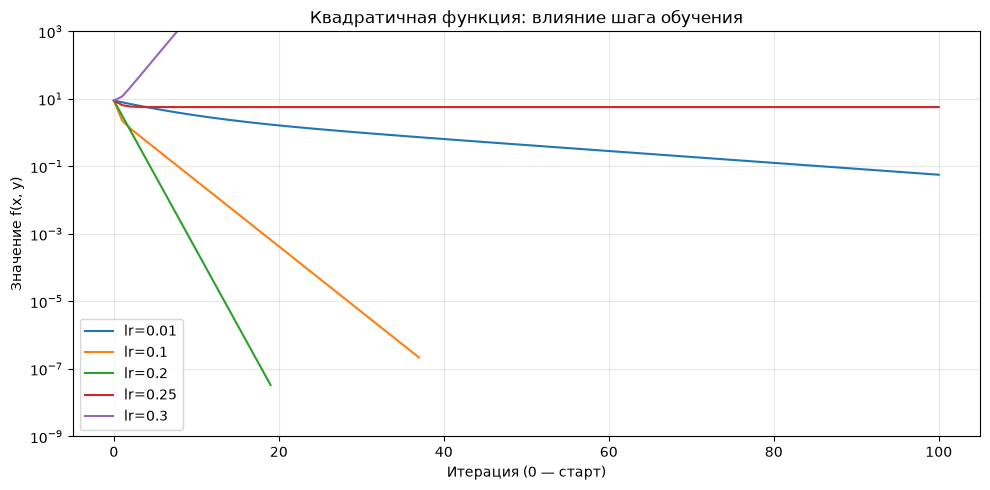

In [148]:
plt.figure(figsize=(10, 5))
plt.yscale('log')
plt.ylim(1e-9, 1e3)
for label, history in results_quadratic.items():
    plt.plot(history['loss'], label=label)
plt.xlabel('Итерация (0 — старт)')
plt.ylabel('Значение f(x, y)')
plt.title('Квадратичная функция: влияние шага обучения')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Ваш ответ:**

По критерию `tol=1e-3` остановились запуски с шагами **0.1 за 37 итераций** и **0.2 за 19 итераций**. Здесь итерация одно обновление параметров; стартовая точка уже включена в историю, поэтому число обновлений равно `len(history['loss']) - 1`.

| Шаг $\eta$ | Итераций | Финальное значение функции | Финальная норма градиента | Результат |
|---|---:|---:|---:|---|
| 0.01 | 100 | 0.0569853 | 0.477436 | Лимит итераций, `tol` не достигнут |
| 0.1 | 37 | $2.18376\cdot10^{-7}$ | 0.000934613 | Остановка по `tol` |
| 0.2 | 19 | $3.34187\cdot10^{-8}$ | 0.000624765 | Остановка по `tol` |
| 0.25 | 100 | 5.76 | 9.6 | Незатухающие колебания |
| 0.3 | 100 | $9.68344\cdot10^{29}$ | $3.93618\cdot10^{15}$ | Расходимость |

Все случаи объясняются покоординатной формулой:

$$x_k=-1.8(1-2\eta)^k,\qquad y_k=1.2(1-8\eta)^k.$$

- **При $\eta=0.01$** координаты каждый раз умножаются на 0.98 и 0.92. Особенно медленно уменьшается $x$: после 100 шагов он ещё равен примерно $-0.238715$, поэтому норма градиента около 0.4774, что гораздо больше $10^{-3}$. Метод движется к минимуму, но 100 итераций недостаточно для заданной точности.
- **При $\eta=0.2$** множитель для $x$ равен 0.6, а для $y$ равен $-0.6$. Обе координаты уменьшаются по модулю, но только $y$ меняет знак на каждом шаге. Поэтому траектория идёт зигзагом по $y$, а $x$ приближается к нулю с одной стороны.
- **При $\eta=0.25$** получаем $x_{k+1}=0.5x_k$, $y_{k+1}=-y_k$. Координата $x$ стремится к нулю, а $y$ чередуется между $1.2$ и $-1.2$. Значение функции стремится к $4\cdot1.2^2=5.76$, но параметры не сходятся к минимуму, а норма градиента стремится к 9.6. Почти постоянный loss здесь **не означает сходимость**: проверка только изменения loss могла бы ошибочно остановить алгоритм.
- **При $\eta=0.3$** множитель для $x$ равен 0.4, а для $y$ равен $-1.4$. Поэтому $x$ стремится к нулю, а $y$ меняет знак и растёт по модулю: спуск расходится.

Для ненулевой стартовой координаты $y$ нужно $|1-8\eta|<1$, то есть **$0<\eta<0.25$**. Для $x$ нужно $|1-2\eta|<1$, то есть $0<\eta<1$. Чтобы обе координаты стремились к нулю, шаг должен удовлетворять более строгому ограничению $0<\eta<0.25$.

Таким образом, допустимый шаг задаёт наиболее крутое направление здесь ось $y$ с кривизной 8. При небольшом устойчивом шаге медленнее уменьшается координата в пологом направлении $x$, потому что её множитель ближе к единице. Точнее, скорость задаётся числом $\max(|1-2\eta|,|1-8\eta|)$: если шаг слишком близок к 0.25, замедляться может уже $y$ из-за почти незатухающих колебаний. Шаг 0.2 уравнивает модули множителей и оказался самым быстрым из предложенных.

### Задание 2.4. Шаг обучения на функции Розенброка (0.5 балла)

Теперь невыпуклая функция Розенброка ($a = 1$, $b = 100$, минимум в точке $(1, 1)$).

1. **(0.15)** Для каждого шага из `learning_rates_rosen` запустите спуск из точки `(-1.5, 2.0)` с `n_iterations=10000` и `tol=1e-3`. Истории сохраните в словарь `results_rosen`, выведите число итераций, финальное значение функции и финальную точку. Если увидите предупреждение `RuntimeWarning: overflow` — это не ошибка в коде, а признак того, что спуск разошёлся.
2. Запустите готовую ячейку с графиками.
3. **(0.1)** Постройте кривые обучения для всех шагов (логарифмическая шкала по $y$). Расходящийся запуск улетает к огромным значениям и растягивает ось — ограничьте её, например `plt.ylim(1e-7, 1e4)`, чтобы остальные кривые было видно.
4. **(0.25)** Ответьте на вопросы:
   - При каком $\eta$ спуск остановился по `tol` около минимума? Сколько итераций понадобилось?
   - Как выглядит траектория: как спуск ведёт себя в начале и как — на дне «оврага»? Почему по дну оврага он движется так медленно?
   - Что произошло при $\eta = 0.0025$?
   - В задании 2.3 хорошо работал шаг 0.1. Почему здесь нельзя взять такой же? Подсказка: сравните норму градиента двух функций в стартовых точках (первое значение в `history['grad_norm']`).

In [149]:
learning_rates_rosen = [0.0001, 0.0005, 0.001, 0.0018, 0.0025]
start_rosen = np.array([-1.5, 2.0])
results_rosen = {}

rosen_rows = []
for lr in learning_rates_rosen:
    gd_rosen = GradientDescent(learning_rate=lr, n_iterations=10000, tol=1e-3)
    # Переполнение при расходящемся запуске ожидается; в таблице останется inf.
    with np.errstate(over='ignore', invalid='ignore'):
        final_point = gd_rosen.fit(rosenbrock_loss, rosenbrock_grad, start_rosen)
    history = gd_rosen.history
    results_rosen[f'lr={lr}'] = history
    if not np.isfinite(history['loss'][-1]):
        status = 'расходимость (inf)'
    elif history['grad_norm'][-1] < 1e-3:
        status = 'tol'
    else:
        status = '10000 итераций'
    rosen_rows.append({
        'learning_rate': lr,
        'итераций': len(history['loss']) - 1,
        'финальный loss': history['loss'][-1],
        'x': final_point[0],
        'y': final_point[1],
        'норма градиента': history['grad_norm'][-1],
        'остановка': status
    })

rosen_summary = pd.DataFrame(rosen_rows)
display(rosen_summary)
print('Норма градиента на старте квадратичной функции:',
      results_quadratic['lr=0.1']['grad_norm'][0])
print('Норма градиента на старте функции Розенброка:',
      results_rosen['lr=0.0018']['grad_norm'][0])
print('Первый шаг Розенброка при eta=0.1:',
      start_rosen - 0.1 * rosenbrock_grad(start_rosen))


,learning_rate,итераций,финальный loss,x,y,норма градиента,остановка
0,0.0001,10000,2.781756,-6.659392e-01,4.514767e-01,2.000524,10000 итераций
1,0.0005,10000,0.006545,9.191685e-01,8.445313e-01,0.077250,10000 итераций
2,0.0010,10000,0.000096,9.902020e-01,9.804606e-01,0.008833,10000 итераций
3,0.0018,8229,0.000001,9.988832e-01,9.977633e-01,0.001000,tol
4,0.0025,8,inf,-2.258160e+119,1.854128e+79,inf,расходимость (inf)


Норма градиента на старте квадратичной функции: 10.252804494381037
Норма градиента на старте функции Розенброка: 162.8649747490233
Первый шаг Розенброка при eta=0.1: [14.  7.]


In [150]:
x_range = np.linspace(-2, 2, 150)
y_range = np.linspace(-1, 3, 150)

plot_gd_2d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска (3D)', min_point=(1, 1))

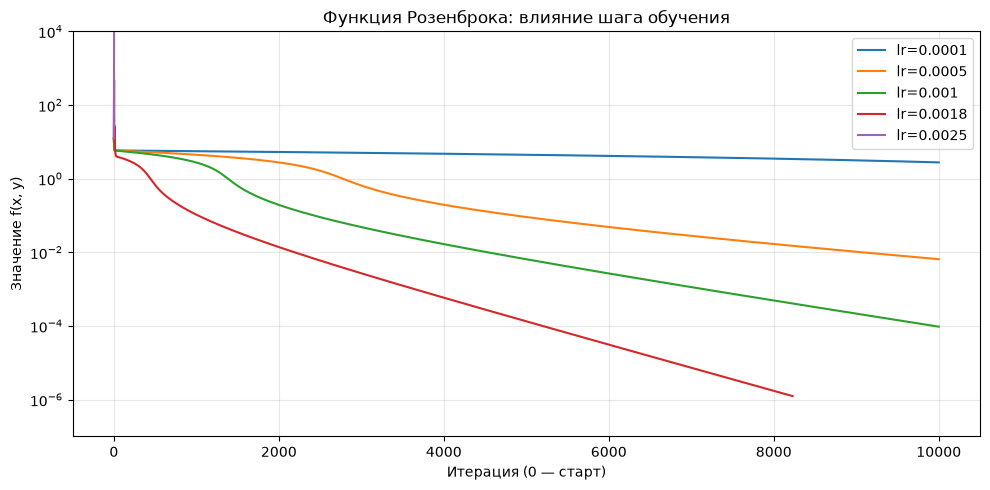

In [151]:
plt.figure(figsize=(10, 5))
plt.yscale('log')
plt.ylim(1e-7, 1e4)
for label, history in results_rosen.items():
    losses = np.asarray(history['loss'])
    finite = np.isfinite(losses)
    plt.plot(np.arange(len(losses))[finite], losses[finite], label=label)
plt.xlabel('Итерация (0 — старт)')
plt.ylabel('Значение f(x, y)')
plt.title('Функция Розенброка: влияние шага обучения')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Ваш ответ:**

За отведённое число итераций критерий `tol=1e-3` выполнился только при **$\eta=0.0018$ на 8229-м шаге**. Финальная точка примерно $(0.998883,\ 0.997763)$, значение функции $1.24913\cdot10^{-6}$, норма градиента $0.000999746$.

| Шаг $\eta$ | Итераций | Финальный loss | Результат |
|---|---:|---:|---|
| 0.0001 | 10000 | 2.781756 | `tol` не достигнут |
| 0.0005 | 10000 | 0.00654525 | `tol` не достигнут |
| 0.001 | 10000 | 0.0000961559 | `tol` не достигнут |
| 0.0018 | 8229 | 0.00000124913 | Остановка по `tol` |
| 0.0025 | 8 | `inf` | Расходимость |

В начале устойчивые запуски быстро спускаются со стенки к узкому оврагу около кривой $y=x^2$. При более крупном шаге заметны колебания поперёк оврага. Затем движение идёт вдоль изгиба к $(1,1)$ и становится медленным: поперёк оврага функция меняется резко, а вдоль него — слабо. Чтобы не вылететь через противоположную стенку, приходится использовать маленький шаг, который даёт небольшой прогресс в пологом направлении. Уменьшение шага до 0.0001 дополнительно замедляет это продвижение.

**При $\eta=0.0025$** шаг оказывается слишком большим для посещаемых областей. Колебания быстро усиливаются, координаты растут, и уже после восьми обновлений loss переполняется до `inf`. Сработала предусмотренная в классе остановка по `np.isfinite(loss)`; это не достижение другого минимума.

Начальная норма градиента квадратичной функции равна примерно **10.2528**, а функции Розенброка **162.865**, то есть почти в 16 раз больше. При $\eta=0.1$ первый шаг Розенброка из $(-1.5,2)$ привёл бы сразу в **$(14,7)$**: здесь градиент равен $(-155,-50)$, поэтому вычитается вектор $(-15.5,-5)$. Такой скачок выводит нас далеко за пределы оврага и резко увеличивает функцию.

Норма градиента определяет длину одного обновления $\eta\|\nabla f\|$, но сама по себе не задаёт границу устойчивости. Допустимый шаг зависит от **кривизны функции**, которая у Розенброка велика и меняется от точки к точке. Поэтому хороший шаг для одной функции нельзя автоматически перенести на другую.

### Задание 2.5. Расписание шага (0.75 балла)

Мы видели дилемму: большой шаг быстро двигает спуск вперёд, но не даёт «успокоиться» у минимума и может разойтись; маленький шаг устойчив, но медленный. Отсюда идея — **менять шаг по ходу обучения** (learning rate schedule): в начале шагать крупно, потом всё мельче: $\eta_k = \eta(k)$.

Популярные расписания:

- **step decay** — уменьшать шаг в $\gamma$ раз каждые несколько итераций: $\eta_k = \eta_0 \cdot \gamma^{\lfloor k / s \rfloor}$;
- **exponential decay** — $\eta_k = \eta_0 \cdot \gamma^k$, $0 < \gamma < 1$;
- **inverse time decay** — $\eta_k = \dfrac{\eta_0}{1 + \text{decay} \cdot k}$. Оно уже реализовано в вашем классе.

Сравним постоянный шаг и inverse time decay на функции Розенброка из точки `(-1.2, 1.0)`, `n_iterations=3000`, без `tol`.

1. **(0.25)** Запустите спуск с постоянным шагом $\eta = 0.003$. Затем — с тем же $\eta_0 = 0.003$ и расписанием: подберите `decay` так, чтобы финальное значение функции было **меньше 0.002**. Попробуйте несколько значений `decay` от `1e-4` до `1e-2` и выведите финальные значения для каждого. Для сравнения запустите ещё и лучший постоянный шаг из 2.4 ($\eta = 0.0018$).
2. **(0.2)** Постройте траектории готовыми функциями (постоянный 0.003, лучший `decay`, постоянный 0.0018) и два графика: кривые обучения (логарифмическая шкала) и шаг обучения $\eta_k$ по итерациям (`history['lr']`).
3. **(0.3)** Ответьте на вопросы:
   - Почему спуск с постоянным шагом 0.003 застрял? Посмотрите на траекторию вблизи дна оврага и на последние точки `history['params'][-4:]`. Дно оврага — кривая $y = x^2$.
   - Как расписание помогло с тем же стартовым шагом?
   - Что получается при слишком большом `decay`, например `1e-2`? А при слишком маленьком?
   - Сравните расписание с постоянным шагом 0.0018. Что лучше и почему?

In [152]:
start_schedule = np.array([-1.2, 1.0])

gd_constant = GradientDescent(learning_rate=0.003, n_iterations=3000, tol=None)
gd_constant.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)

gd_small_constant = GradientDescent(learning_rate=0.0018, n_iterations=3000, tol=None)
gd_small_constant.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)

decay_candidates = [1e-4, 2e-4, 3e-4, 5e-4, 1e-3, 3e-3, 1e-2]
results_decay = {}
decay_rows = []
for decay in decay_candidates:
    gd_schedule = GradientDescent(learning_rate=0.003, n_iterations=3000,
                                 decay=decay, tol=None)
    gd_schedule.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
    results_decay[decay] = gd_schedule.history
    decay_rows.append({
        'decay': decay,
        'финальный loss': gd_schedule.history['loss'][-1],
        'последний шаг': gd_schedule.history['lr'][-1]
    })

display(pd.DataFrame(decay_rows))
best_decay = min(decay_candidates, key=lambda d: results_decay[d]['loss'][-1])
best_decay_history = results_decay[best_decay]
print(f'Лучший decay из сетки: {best_decay:g}, '
      f'loss={best_decay_history["loss"][-1]:.9f}')
print('Условие loss < 0.002 выполнено:', best_decay_history['loss'][-1] < 0.002)
print(f'Постоянный шаг 0.003: loss={gd_constant.history["loss"][-1]:.9f}')
print(f'Постоянный шаг 0.0018: loss={gd_small_constant.history["loss"][-1]:.9f}')

results_schedule = {
    'Постоянный шаг 0.003': gd_constant.history,
    f'0.003 / (1 + {best_decay:g} k)': best_decay_history,
    'Постоянный шаг 0.0018': gd_small_constant.history
}
last_points = pd.DataFrame(gd_constant.history['params'][-4:], columns=['x', 'y'])
last_points['y - x2'] = last_points['y'] - last_points['x']**2
print('Последние 4 точки при постоянном шаге 0.003:')
display(last_points)


,decay,финальный loss,последний шаг
0,0.0001,0.083900,0.002308
1,0.0002,0.000439,0.001875
2,0.0003,0.000742,0.001579
3,0.0005,0.001615,0.001200
4,0.0010,0.005212,0.000750
5,0.0030,0.031859,0.000300
6,0.0100,0.172087,0.000097


Лучший decay из сетки: 0.0002, loss=0.000438951
Условие loss < 0.002 выполнено: True
Постоянный шаг 0.003: loss=0.325722257
Постоянный шаг 0.0018: loss=0.002566418
Последние 4 точки при постоянном шаге 0.003:


,x,y,y - x2
0,0.785954,0.566971,-0.050753
1,0.739371,0.597423,0.050753
2,0.785965,0.566971,-0.050771
3,0.739365,0.597433,0.050773


In [153]:
x_range_schedule = np.linspace(-1.5, 1.3, 140)
y_range_schedule = np.linspace(-0.2, 2.0, 140)
plot_gd_2d(rosenbrock_loss, results_schedule, x_range_schedule, y_range_schedule,
           title='Розенброк: постоянный шаг и inverse time decay', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results_schedule, x_range_schedule, y_range_schedule,
           title='Розенброк: сравнение расписаний (3D)', min_point=(1, 1))


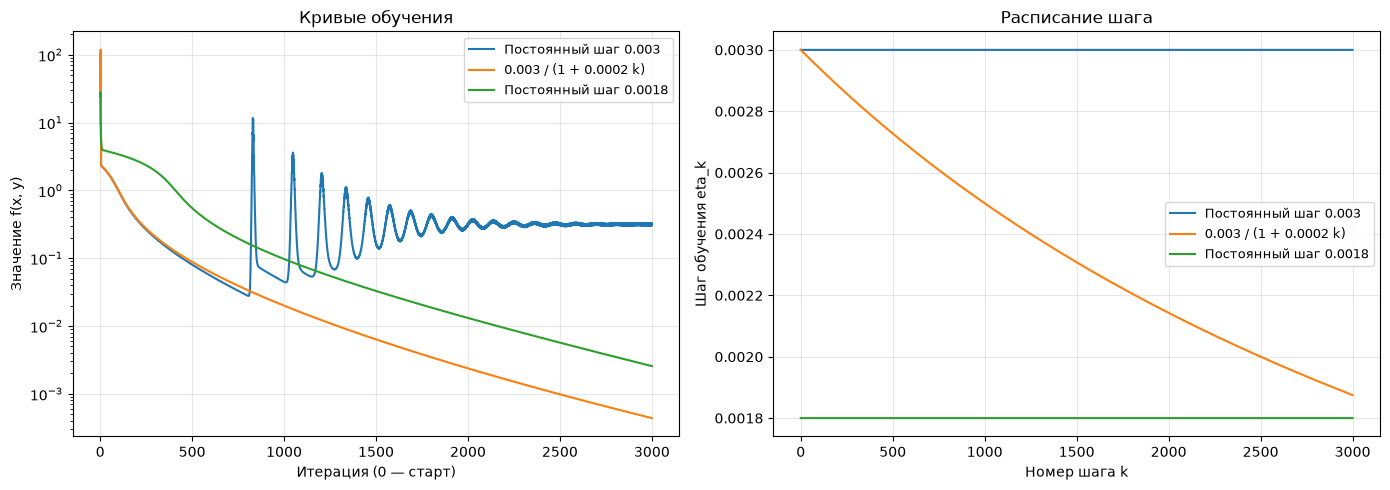

In [154]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in results_schedule.items():
    axes[0].plot(history['loss'], label=label)
    axes[1].plot(history['lr'], label=label)
axes[0].set_yscale('log')
axes[0].set_xlabel('Итерация (0 — старт)')
axes[0].set_ylabel('Значение f(x, y)')
axes[0].set_title('Кривые обучения')
axes[1].set_xlabel('Номер шага k')
axes[1].set_ylabel('Шаг обучения eta_k')
axes[1].set_title('Расписание шага')
for ax in axes:
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Ваш ответ:**

В проверенной сетке лучший результат дало расписание

$$\eta_k=\frac{0.003}{1+0.0002k}.$$

После 3000 шагов получился **loss $\approx0.000438951<0.002$**, финальная точка примерно $(0.979066,\ 0.958485)$. Последний использованный шаг, с индексом $k=2999$, равен примерно 0.00187523.

| `decay` | Loss после 3000 шагов |
|---:|---:|
| 0.0001 | 0.083899510 |
| **0.0002** | **0.000438951** |
| 0.0003 | 0.000742099 |
| 0.0005 | 0.001614884 |
| 0.001 | 0.005211854 |
| 0.003 | 0.031859291 |
| 0.01 | 0.172086919 |

**Почему постоянный шаг 0.003 перестал давать прогресс.** Последние четыре точки почти чередуются между $(0.78596,\ 0.56697)$ и $(0.73937,\ 0.59743)$. Величина $y-x^2$ у них поочерёдно примерно $-0.0508$ и $+0.0508$: алгоритм перескакивает через дно оврага с одной стороны на другую. Финальный loss около **0.325722**, а норма градиента около **18.56**. Это колебания из-за слишком крупного шага, а не остановка в локальном минимуме.

**Как помогло расписание.** В начале оно сохраняет возможность двигаться достаточно быстро, а затем уменьшает размер обновлений. Колебания около оврага затухают, и алгоритм может дальше приближаться к $(1,1)$ с тем же стартовым шагом 0.003. В истории 3001 значение функции и 3000 значений шага: стартовая точка уже имеет loss, но ещё не имеет сделанного шага.

**Слишком большой `decay`.** При 0.01 шаг к концу уменьшается примерно до $9.68\cdot10^{-5}$. Он становится маленьким слишком рано, поэтому за фиксированные 3000 обновлений метод не успевает пройти вдоль оврага; loss около 0.172087. Это недостаточный прогресс за данный бюджет, а не доказательство отсутствия сходимости при дальнейшем продолжении.

**Слишком маленький `decay`.** При 0.0001 последний шаг ещё около 0.00230787: уменьшение недостаточно сильное, колебания мешают точному приближению к минимуму, и loss остаётся около 0.0838995. При `decay=0` получился бы исходный постоянный шаг 0.003.

**Сравнение с постоянным шагом 0.0018.** Из той же стартовой точки и за те же 3000 обновлений он даёт loss около **0.00256642**. Лучшее проверенное расписание даёт примерно в **5.85 раза меньший loss**: более крупные начальные шаги помогают быстрее пройти раннюю часть пути, а последующее уменьшение обеспечивает устойчивость ближе к минимуму. Это результат для данного старта, бюджета и сетки; расписание тоже нужно подбирать, и произвольный `decay` не обязан улучшать постоянный шаг.


### Задание 2.6. Градиентный спуск для линейной регрессии (1 балл)

Вернёмся к машинам и обучим линейную регрессию из 1.4 своим `GradientDescent`.

Добавим к признакам столбец из единиц — тогда свободный член (intercept) станет обычным весом $w_0$. Для матрицы признаков $X$ размера $n \times (d+1)$ и вектора весов $w$:
$$L(w) = \frac{1}{n}\,\|Xw - y\|^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i^\top w - y_i)^2, \qquad \nabla L(w) = \frac{2}{n}\,X^\top (Xw - y).$$

1. **(0.25)** Реализуйте `mse_loss(w, X, y)` и `mse_grad(w, X, y)` по этим формулам — без циклов, через матричные операции NumPy (`@` — матричное умножение, `.T` — транспонирование).
2. **(0.25)** Запустите спуск из $w_0 = 0$ (`np.zeros(X_gd.shape[1])`) на `X_gd`, `y_gd` из ячейки ниже для шагов `[0.01, 0.1, 0.3, 0.5]` с `n_iterations=1000` и `tol=1`. Класс ожидает функции от одного аргумента `w`, поэтому передавайте `lambda w: mse_loss(w, X_gd, y_gd)` (и так же для градиента). Выведите для каждого шага число итераций и финальный loss, постройте кривые обучения (логарифмическая шкала; у расходящегося запуска в истории окажется `inf`, поэтому задайте пределы оси, например `plt.ylim(1e11, 1e13)`). При каком шаге спуск разошёлся?
3. **(0.25)** Сравните веса лучшего запуска с `lin_reg_scaled` из 1.4 (`intercept_` и `coef_`), сведите их в таблицу. Посчитайте $R^2$ своей модели на test: не забудьте добавить столбец единиц к `X_test_scaled`.
4. **(0.25)** Повторите спуск на **нестандартизированных** признаках: `X_train` из 1.1 со столбцом единиц, шаг `1e-10`, 1000 итераций (с шагом побольше спуск расходится, можете проверить). Сравните финальный loss с результатом на стандартизированных признаках. Почему без стандартизации спуск не справляется? Свяжите ответ с заданием 2.3.

In [155]:
# матрица признаков со столбцом единиц (для intercept) и таргет в виде массивов NumPy
X_gd = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
y_gd = y_train.to_numpy()
print(X_gd.shape, y_gd.shape)

(5843, 7) (5843,)


In [156]:
def mse_loss(w, X, y):
    return np.mean((X @ w - y)**2)


def mse_grad(w, X, y):
    return (2 / X.shape[0]) * (X.T @ (X @ w - y))


In [157]:
# Проверка. Для квадратичной функции центральная разность точна при любом h, поэтому берём h=1
w_check = np.arange(X_gd.shape[1], dtype=float)
assert np.isclose(mse_loss(w_check, X_gd, y_gd), mean_squared_error(y_gd, X_gd @ w_check)), 'mse_loss считает неверно'
assert np.allclose(mse_grad(w_check, X_gd, y_gd),
                   numerical_grad(lambda w: mse_loss(w, X_gd, y_gd), w_check, h=1.0), rtol=1e-6), 'mse_grad считает неверно'
print('mse_loss и mse_grad посчитаны верно.')

mse_loss и mse_grad посчитаны верно.


GD, learning_rate=0.01: 1000 итераций
Train: R^2 = 0.5921, MSE = 116853792539.47
Test:  R^2 = 0.5939, MSE = 233439333200.28
GD, learning_rate=0.1: tol
Train: R^2 = 0.5921, MSE = 116851699648.09
Test:  R^2 = 0.5940, MSE = 233395084982.45
GD, learning_rate=0.3: tol
Train: R^2 = 0.5921, MSE = 116851699647.95
Test:  R^2 = 0.5940, MSE = 233395083270.69
GD, learning_rate=0.5: расходимость (inf)
Конечных метрик нет: значение MSE переполнилось до inf.


,learning_rate,итераций,финальный MSE train,норма градиента,остановка
0,0.01,1000,1.168538e+11,1.152529e+03,1000 итераций
1,0.10,318,1.168517e+11,9.737411e-01,tol
2,0.30,103,1.168517e+11,9.267434e-01,tol
3,0.50,727,inf,8.414587e+152,расходимость (inf)


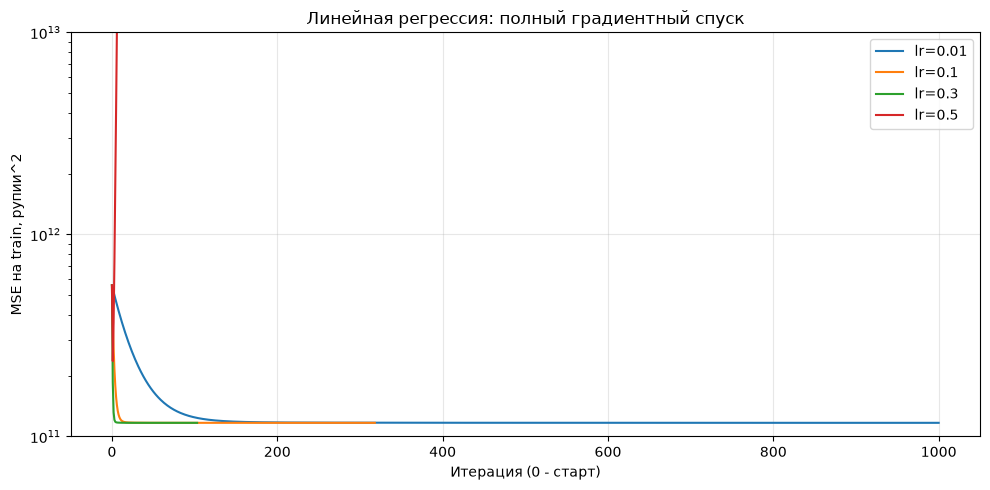

In [158]:
learning_rates_linreg = [0.01, 0.1, 0.3, 0.5]
results_linreg = {}


class GDLinearRegression:
    def __init__(self, weights):
        self.intercept_ = float(weights[0])
        self.coef_ = np.asarray(weights[1:], dtype=float).copy()

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_


linreg_rows = []
for lr in learning_rates_linreg:
    gd_linreg = GradientDescent(learning_rate=lr, n_iterations=1000, tol=1)
    with np.errstate(over='ignore', invalid='ignore'):
        weights = gd_linreg.fit(lambda w: mse_loss(w, X_gd, y_gd),
                                lambda w: mse_grad(w, X_gd, y_gd),
                                np.zeros(X_gd.shape[1]))
    history = gd_linreg.history
    results_linreg[f'lr={lr}'] = history
    if not np.isfinite(history['loss'][-1]):
        status = 'расходимость (inf)'
    elif history['grad_norm'][-1] < 1:
        status = 'tol'
    else:
        status = '1000 итераций'
    linreg_rows.append({
        'learning_rate': lr,
        'итераций': len(history['loss']) - 1,
        'финальный MSE train': history['loss'][-1],
        'норма градиента': history['grad_norm'][-1],
        'остановка': status
    })
    print(f'GD, learning_rate={lr}: {status}')
    if np.isfinite(history['loss'][-1]):
        print_metrics(GDLinearRegression(weights), X_train_scaled, y_train,
                      X_test_scaled, y_test)
    else:
        print('Конечных метрик нет: значение MSE переполнилось до inf.')

linreg_summary = pd.DataFrame(linreg_rows)
display(linreg_summary)

plt.figure(figsize=(10, 5))
plt.yscale('log')
plt.ylim(1e11, 1e13)
for label, history in results_linreg.items():
    losses = np.asarray(history['loss'])
    finite = np.isfinite(losses)
    plt.plot(np.arange(len(losses))[finite], losses[finite], label=label)
plt.xlabel('Итерация (0 - старт)')
plt.ylabel('MSE на train, рупии^2')
plt.title('Линейная регрессия: полный градиентный спуск')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [159]:
# Лучший запуск определяем только по конечному MSE на train.
finite_linreg = {label: history for label, history in results_linreg.items()
                 if np.isfinite(history['loss'][-1])}
best_linreg_key = min(finite_linreg, key=lambda label: finite_linreg[label]['loss'][-1])
best_weights = np.array(results_linreg[best_linreg_key]['params'][-1])
sklearn_weights = np.r_[lin_reg_scaled.intercept_, lin_reg_scaled.coef_]
weights_comparison = pd.DataFrame({
    'признак': ['intercept'] + num_features,
    'наш GD': best_weights,
    'LinearRegression': sklearn_weights,
    'абсолютная разница': np.abs(best_weights - sklearn_weights)
})
print('Лучший запуск:', best_linreg_key)
display(weights_comparison)

X_test_gd = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])
y_pred_gd = X_test_gd @ best_weights
print(f'R2 собственного GD на test: {r2_score(y_test, y_pred_gd):.9f}')
print(f'MSE собственного GD на test: {mean_squared_error(y_test, y_pred_gd):.3f}')
print(f'R2 sklearn на test: {r2_score(y_test, lin_reg_scaled.predict(X_test_scaled)):.9f}')


Лучший запуск: lr=0.3


,признак,наш GD,LinearRegression,абсолютная разница
0,intercept,522967.813110,522967.813110,5.820766e-11
1,year,152898.696383,152898.498205,1.981785e-01
2,km_driven,-43954.029712,-43953.853566,1.761464e-01
3,mileage,28791.922338,28791.816950,1.053881e-01
4,engine,61373.292038,61371.072884,2.219153e+00
5,max_power,322548.708506,322550.136077,1.427572e+00
6,seats,-23442.273501,-23441.054866,1.218635e+00


R2 собственного GD на test: 0.593974445
MSE собственного GD на test: 233395083270.688
R2 sklearn на test: 0.593974504


Без стандартизации: 1000 итераций, MSE train=317025976603.068
Train: R^2 = -0.1066, MSE = 317025976603.07
Test:  R^2 = -0.1145, MSE = 640666785317.00
Отношение MSE без стандартизации к лучшему MSE после стандартизации: 2.7130626046365007


,признаки,максимальная кривизна,верхняя граница шага (строгая)
0,стандартизированные,5.187180e+00,3.855659e-01
1,исходные,1.814161e+10,1.102438e-10


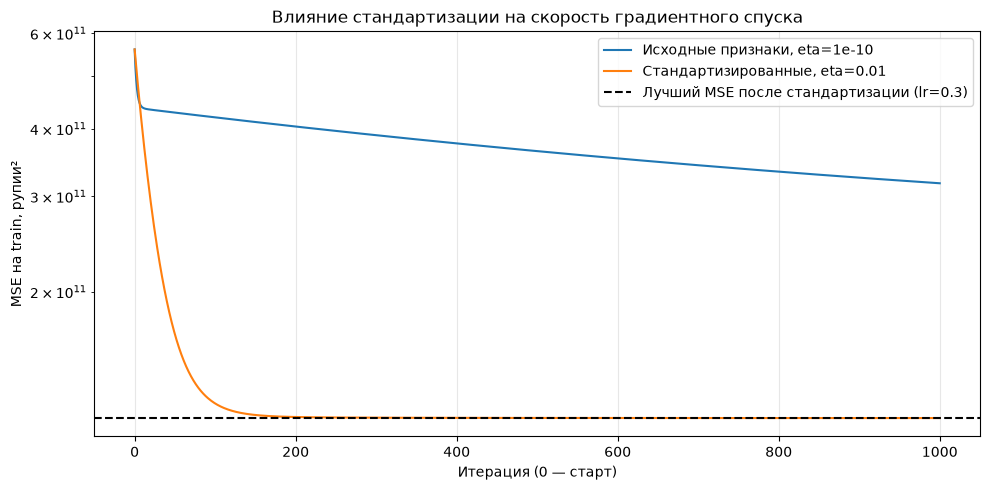

In [160]:
# При реализации использован ChatGPT
X_gd_raw = np.hstack([np.ones((X_train.shape[0], 1)), X_train.to_numpy()])
gd_raw = GradientDescent(learning_rate=1e-10, n_iterations=1000, tol=None)
weights_raw = gd_raw.fit(lambda w: mse_loss(w, X_gd_raw, y_gd),
                         lambda w: mse_grad(w, X_gd_raw, y_gd),
                         np.zeros(X_gd_raw.shape[1]))
print(f'Без стандартизации: {len(gd_raw.history["loss"]) - 1} итераций, '
      f'MSE train={gd_raw.history["loss"][-1]:.3f}')
print_metrics(GDLinearRegression(weights_raw), X_train, y_train, X_test, y_test)
print('Отношение MSE без стандартизации к лучшему MSE после стандартизации:',
      gd_raw.history['loss'][-1] / results_linreg[best_linreg_key]['loss'][-1])

# MSE — квадратичная функция весов. Её матрица кривизны равна 2 X.T @ X / n.
# Для устойчивости постоянного шага требуется eta < 2 / lambda_max.
lambda_max_scaled = np.linalg.eigvalsh(2 * (X_gd.T @ X_gd) / len(y_gd))[-1]
lambda_max_raw = np.linalg.eigvalsh(2 * (X_gd_raw.T @ X_gd_raw) / len(y_gd))[-1]
display(pd.DataFrame({
    'признаки': ['стандартизированные', 'исходные'],
    'максимальная кривизна': [lambda_max_scaled, lambda_max_raw],
    'верхняя граница шага (строгая)': [2 / lambda_max_scaled, 2 / lambda_max_raw]
}))

plt.figure(figsize=(10, 5))
plt.plot(gd_raw.history['loss'], label='Исходные признаки, eta=1e-10')
plt.plot(results_linreg['lr=0.01']['loss'], label='Стандартизированные, eta=0.01')
plt.axhline(results_linreg[best_linreg_key]['loss'][-1], color='black', linestyle='--',
            label=f'Лучший MSE после стандартизации ({best_linreg_key})')
plt.yscale('log')
plt.xlabel('Итерация (0 — старт)')
plt.ylabel('MSE на train, рупии²')
plt.title('Влияние стандартизации на скорость градиентного спуска')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Ваш ответ:**

Для вектора ошибок $e=Xw-y$ функция потерь равна $e^Te/n$. Дифференцируя квадратичную форму, получаем

$$\nabla L(w)=\frac{2}{n}X^T(Xw-y).$$

Обе функции реализованы матричными операциями без циклов. После добавления единичного столбца $X$ имеет размер $(5843,7)$, а вектор параметров и градиент  длину 7. Первый вес  свободный член; при прогнозе на test добавляется такой же столбец единиц.

| Шаг | Итераций | MSE train, млрд рупий$^2$ | $R^2$ test | Результат |
|---:|---:|---:|---:|---|
| 0.01 | 1000 | 116.853793 | 0.593897466 | Лимит итераций |
| 0.1 | 318 | 116.851700 | 0.593974442 | Остановка по `tol` |
| **0.3** | **103** | **116.851700** | **0.593974445** | Остановка по `tol` |
| 0.5 | 727 | `inf` | - | Расходимость |

Остановка по `tol` здесь означает, что **норма градиента меньше порога 1**. У шага 0.01 за 1000 итераций этот критерий ещё не выполнен, но MSE уже близка к оптимальной: этот запуск тоже значительно улучшил модель. Шаги 0.1 и 0.3 дошли до заданной точности, причём 0.3 потребовал меньше обновлений. При 0.5 значение MSE растёт и затем переполняется.

**Сравнение со sklearn.** Лучшим по конечному MSE **на train** оказался запуск с шагом 0.3. Его веса практически совпали с `lin_reg_scaled`: максимальная абсолютная разница коэффициентов около **2.22** при самих коэффициентах порядка десятков и сотен тысяч. Свободный член примерно **522967.813**. Небольшая разница ожидаема: GD остановлен при норме градиента меньше 1, а не в точном минимуме.

Для собственного GD на test получились $R^2\approx0.593974445$ и MSE $\approx233395083270.688$ рупий². У sklearn $R^2\approx0.593974504$: качество практически одинаковое. Это подтверждает, что самостоятельно реализованный алгоритм минимизирует ту же MSE.

**Без стандартизации** при шаге $10^{-10}$ и 1000 итерациях MSE train остаётся около **317025976603.068** рупий² примерно в **2.71 раза выше** результата после стандартизации. Получились $R^2_{train}\approx-0.106557$ и $R^2_{test}\approx-0.114535$; MSE test около **640666785317.001** рупий². Отрицательный $R^2$ на train здесь не противоречит свойству МНК из части 1: тот результат относится к найденному минимуму регрессии со свободным членом, а данный запуск GD до него ещё не дошёл.

Причина сильно разные масштабы признаков. Например, пробег измеряется десятками тысяч километров, а число мест единицами. Поверхность MSE по весам становится сильно вытянутой: большой шаг приводит к расходимости в крутых направлениях, а вынужденно маленький шаг почти не продвигает алгоритм в пологих. Это тот же эффект, который наблюдался для $x^2+4y^2$, только разница масштабов гораздо сильнее.

Дополнительная численная проверка показывает это через матрицу кривизны $H=2X^TX/n$. Для постоянного шага квадратичной функции условие устойчивости имеет вид $0<\eta<2/\lambda_{max}(H)$. После стандартизации $\lambda_{max}\approx5.18718$, поэтому верхняя граница шага около **0.385566**: шаг 0.3 допустим, а 0.5 слишком велик. Без стандартизации $\lambda_{max}\approx1.81416\cdot10^{10}$ и граница около **$1.10244\cdot10^{-10}$**: использованный шаг $10^{-10}$ едва помещается в устойчивый диапазон.

Стандартизация не меняет множество возможных линейных прогнозов при наличии intercept. Она меняет геометрию задачи в координатах весов и поэтому позволяет градиентному спуску гораздо быстрее найти практически тот же минимум.

### Задание 2.7. Стохастический градиентный спуск (0.5 балла)

В стохастическом (mini-batch) градиентном спуске (SGD) градиент на каждом шаге считаем не по всей выборке, а по небольшому случайному подмножеству объектов — **батчу** (batch). Шаг становится намного дешевле, но градиент — шумным.

Нашему классу можно просто передать другую функцию градиента. Loss при этом по-прежнему считается по всей выборке, так кривые обучения удобно сравнивать.

1. **(0.2)** Допишите `mse_grad_batch(w, batch_size)`: выберите `batch_size` случайных номеров объектов без повторов (`rng.choice(n, size=batch_size, replace=False)`) и верните градиент MSE только по этим объектам (используйте `mse_grad`).
2. **(0.15)** Обучите SGD на `X_gd`, `y_gd` с `batch_size` 1, 32 и 256: шаг 0.01, 1000 итераций, `tol=None`. Постройте кривые обучения вместе с полным GD с тем же шагом.
3. **(0.15)** Ответьте: как размер батча влияет на вид кривой и на финальный loss? Почему для SGD не годится критерий остановки по норме градиента?

SGD, batch_size=1, итераций=1000
Train: R^2 = -0.1721, MSE = 335809120100.58
Test:  R^2 = 0.2071, MSE = 455800935174.57
SGD, batch_size=32, итераций=1000
Train: R^2 = 0.5911, MSE = 117143543899.81
Test:  R^2 = 0.5892, MSE = 236113483396.06
SGD, batch_size=256, итераций=1000
Train: R^2 = 0.5918, MSE = 116962161133.24
Test:  R^2 = 0.5885, MSE = 236539119104.33


,метод,финальный MSE train
0,"SGD, batch=1",3.358091e+11
1,"SGD, batch=32",1.171435e+11
2,"SGD, batch=256",1.169622e+11
3,"Полный GD, batch=5843",1.168538e+11


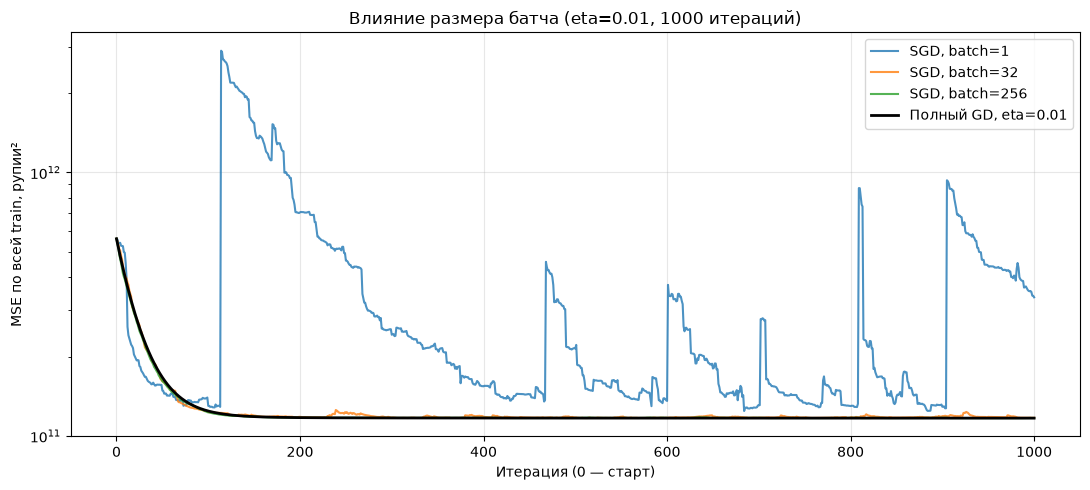

In [161]:
rng = np.random.default_rng(42)


# При реализации использован ChatGPT.
def mse_grad_batch(w, batch_size):
    idx = rng.choice(X_gd.shape[0], size=batch_size, replace=False)
    return mse_grad(w, X_gd[idx], y_gd[idx])


# Единый генератор с seed=42 делает всю последовательность запусков воспроизводимой.
results_sgd = {}
sgd_rows = []
for batch_size in [1, 32, 256]:
    gd_sgd = GradientDescent(learning_rate=0.01, n_iterations=1000, tol=None)
    weights_sgd = gd_sgd.fit(lambda w: mse_loss(w, X_gd, y_gd),
                             lambda w: mse_grad_batch(w, batch_size),
                             np.zeros(X_gd.shape[1]))
    results_sgd[batch_size] = gd_sgd.history
    print(f'SGD, batch_size={batch_size}, '
          f'итераций={len(gd_sgd.history["loss"]) - 1}')
    print_metrics(GDLinearRegression(weights_sgd), X_train_scaled, y_train,
                  X_test_scaled, y_test)
    sgd_rows.append({'метод': f'SGD, batch={batch_size}',
                     'финальный MSE train': gd_sgd.history['loss'][-1]})

sgd_rows.append({'метод': f'Полный GD, batch={len(y_gd)}',
                 'финальный MSE train': results_linreg['lr=0.01']['loss'][-1]})
sgd_summary = pd.DataFrame(sgd_rows)
display(sgd_summary)

plt.figure(figsize=(11, 5))
for batch_size, history in results_sgd.items():
    plt.plot(history['loss'], label=f'SGD, batch={batch_size}', alpha=0.8)
plt.plot(results_linreg['lr=0.01']['loss'], label='Полный GD, eta=0.01',
         color='black', linewidth=2)
plt.yscale('log')
plt.xlabel('Итерация (0 — старт)')
plt.ylabel('MSE по всей train, рупии²')
plt.title('Влияние размера батча (eta=0.01, 1000 итераций)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Ваш ответ:**

Случайный батч выбирается без повторов **внутри одного шага**. На следующем шаге выбор делается заново, поэтому тот же объект может встретиться снова. Градиент по батчу вычисляется той же функцией `mse_grad`, но делится уже на размер этого батча. Полный loss во всех историях по-прежнему считается по всем 5843 объектам train.

Для указанного `seed=42`, последовательного запуска батчей 1, 32, 256 и 1000 обновлений с шагом 0.01 получились:

| Метод | Финальный MSE train, млрд рупий$^2$ |
|---|---:|
| SGD, batch = 1 | 335.809120 |
| SGD, batch = 32 | 117.143544 |
| SGD, batch = 256 | 116.962161 |
| Полный GD, batch = 5843 | 116.853793 |

**Влияние размера батча.** При одном объекте направление очень шумное: на графике видны резкие всплески, и финальный loss в этом запуске намного хуже полного GD. Градиенты отдельных объектов могут значительно отличаться от среднего градиента. Батч 32 уже сглаживает эту случайность, а батч 256 даёт ещё более гладкую кривую и меньший конечный train loss. Оба результата близки к полному GD, у которого здесь loss плавно убывает.

Увеличение батча обычно уменьшает разброс оценки градиента, но не гарантирует монотонного улучшения каждой метрики в одном случайном эксперименте. Например, здесь $R^2$ на test у батча 32 примерно **0.589245**, а у батча 256 примерно **0.588505**: немного лучше оказался батч 32, хотя у 256 меньше train loss. Оценка по test не использовалась для подбора батча.

**Почему не используем остановку по норме случайного градиента.** Даже в минимуме полной MSE градиенты отдельных объектов обычно ненулевые: их положительные и отрицательные вклады компенсируются только при усреднении. Поэтому норма градиента случайного батча может оставаться большой рядом с минимумом. Возможна и обратная ситуация: случайный батч даёт маленький градиент далеко от минимума полной функции. Одна такая проверка может либо слишком долго не срабатывать, либо остановить обучение преждевременно.

Здесь поэтому задано `tol=None` и фиксированы 1000 обновлений. В других задачах можно проверять устойчивое изменение усреднённого loss за несколько шагов или периодически вычислять полный градиент. При постоянном ненулевом шаге SGD также обычно продолжает колебаться около решения; уменьшение шага помогает снизить эти колебания.

Меньший батч удешевляет **вычисление градиента одного обновления**, но в этом учебном классе полный loss всё равно вычисляется на каждом шаге. Поэтому по данному эксперименту нельзя автоматически заключить, что SGD быстрее по времени. Кроме того, одинаковые 1000 обновлений у разных батчей не означают одинаковое число обработанных примеров при вычислении градиентов.


## Чек-лист перед сдачей

- [ ] Перезапустил ядро и выполнил все ячейки сверху вниз — ошибок нет.
- [ ] Все выводы и графики сохранены в ноутбуке.
- [ ] Ответил текстом на все вопросы.
- [ ] Если пользовался LLM или чужим кодом, указал это.